# ВШЭ 2026: Математические методы анализа данных

## Семинар 10: Обнаружение аномалий и понижение размерности

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets
import warnings
warnings.filterwarnings("ignore")

# Содержание

## Обнаружение аномалий
- [Метод опорных векторов одного класса](#one-class_svm)
- [Изолирующий лес](#isolation_forest)
- [CUSUM](#cumsum)

## Понижение размерности
- [Метод главных компонент (PCA)](#pca)
- [Сингулярное разложение (SVD)](#svd)
- [SVD на лицах: «собственные лица»](#eigenfaces)
- [Бонус: сжатие фотографии с помощью SVD](#svd_image)
- [t-SNE: нелинейное понижение размерности для визуализации](#tsne)


## Подготовка данных и разведочный анализ (EDA)

In [2]:
data = pd.read_csv('https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv', sep=';')
# data = pd.read_csv('winequality-white.csv', sep=';')
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [3]:
data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


array([[<Axes: title={'center': 'fixed acidity'}>,
        <Axes: title={'center': 'volatile acidity'}>,
        <Axes: title={'center': 'citric acid'}>],
       [<Axes: title={'center': 'residual sugar'}>,
        <Axes: title={'center': 'chlorides'}>,
        <Axes: title={'center': 'free sulfur dioxide'}>],
       [<Axes: title={'center': 'total sulfur dioxide'}>,
        <Axes: title={'center': 'density'}>,
        <Axes: title={'center': 'pH'}>],
       [<Axes: title={'center': 'sulphates'}>,
        <Axes: title={'center': 'alcohol'}>,
        <Axes: title={'center': 'quality'}>]], dtype=object)

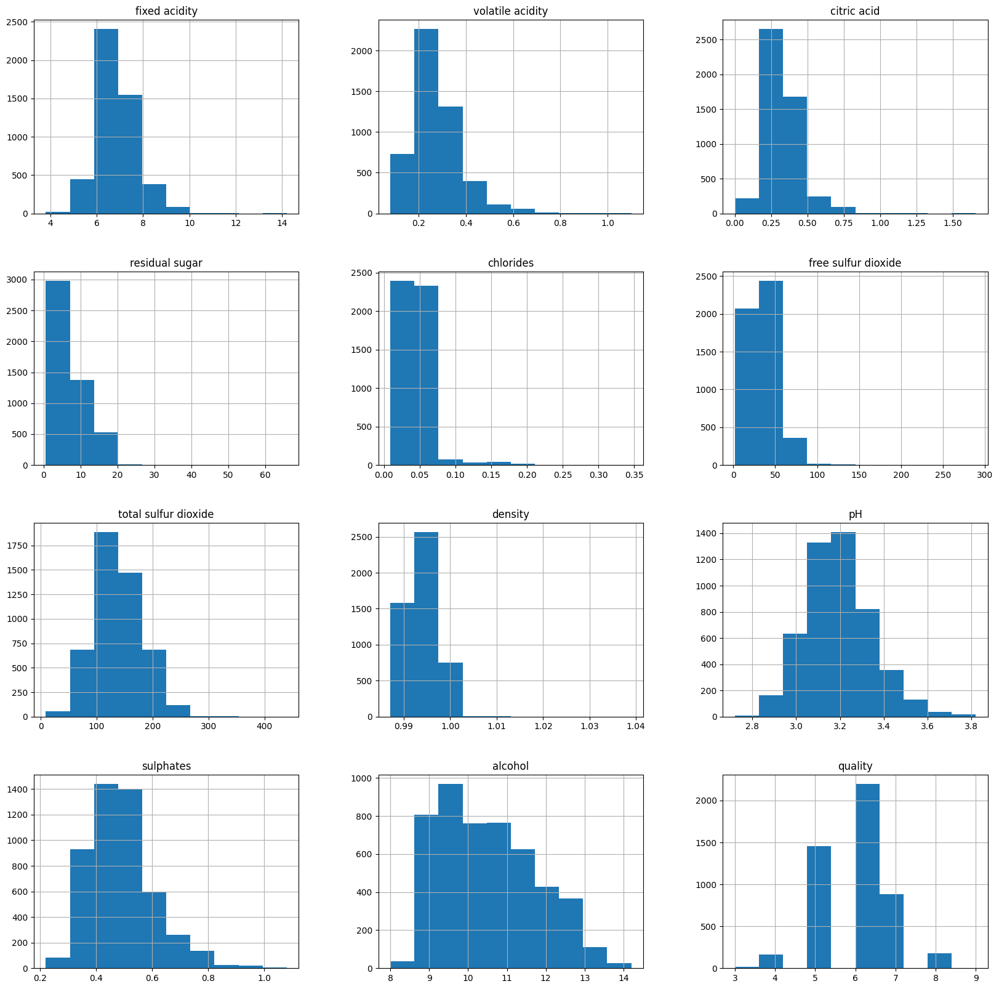

In [5]:
data.hist(figsize=(20, 20))

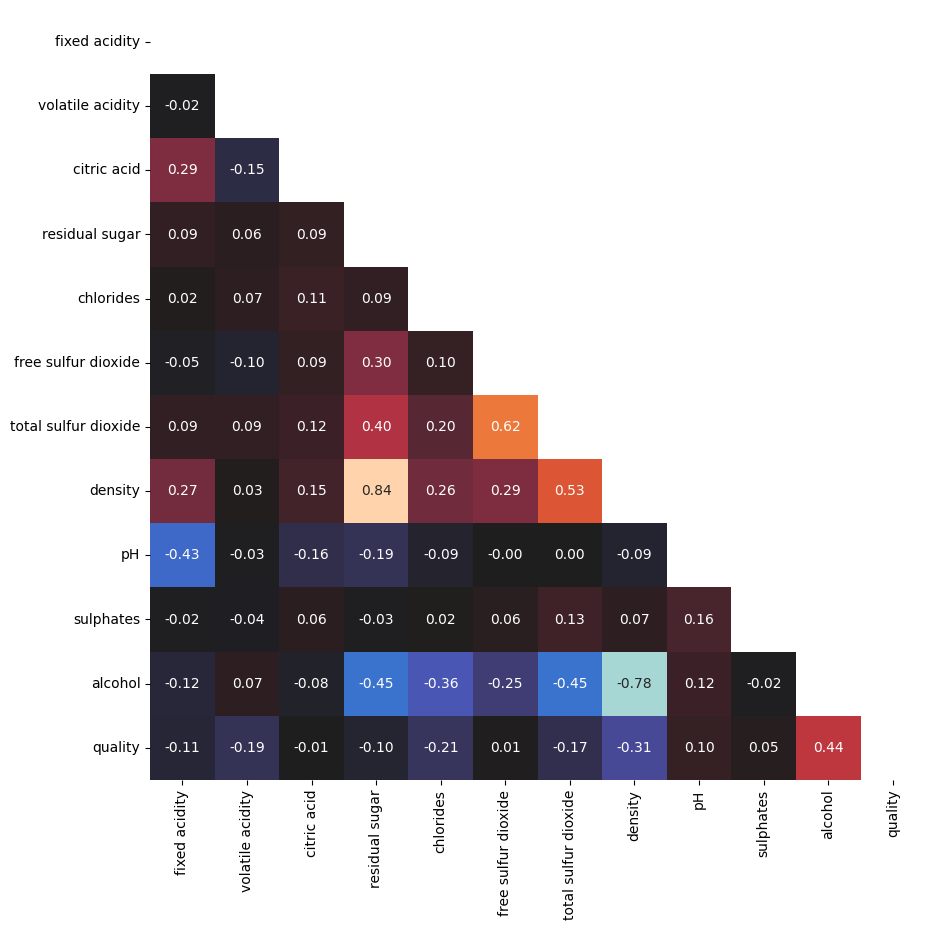

In [6]:
plt.figure(figsize=(10,10))

corr_matrix = data.corr()
lower = corr_matrix.where(np.tril(np.ones(corr_matrix.shape), k=-1).astype(bool))

sns.heatmap(lower, annot=True, fmt='.2f', cbar=False, center=0);

In [7]:
high_corr = [
    column for column in lower.columns if any((lower[column] > 0.6)|(lower[column] < -0.6))
]
high_corr

['residual sugar', 'free sulfur dioxide', 'density']

In [8]:
other_features = [col for col in data.columns if col not in high_corr and col!='quality']

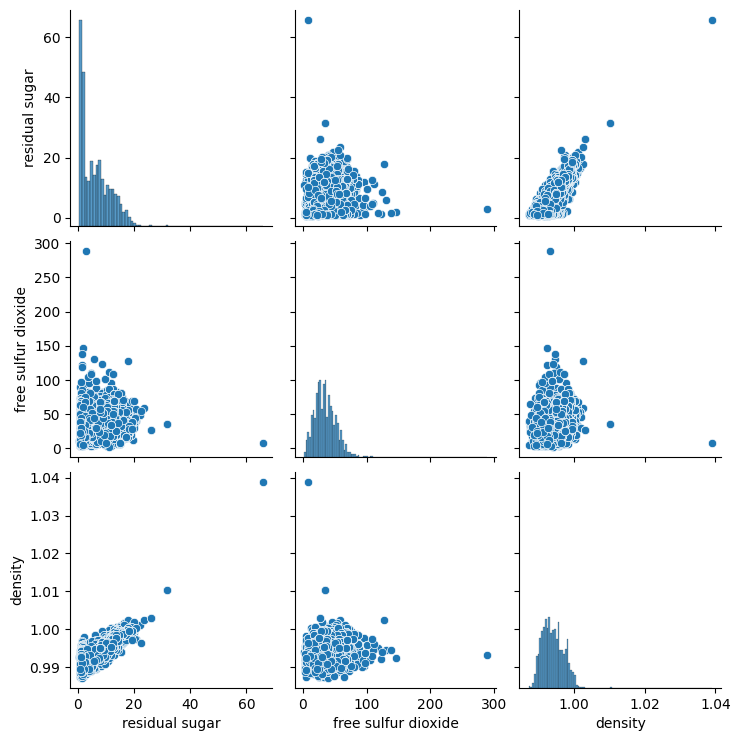

In [9]:
sns.pairplot(data[high_corr]);

## Простой метод

### 3-$\sigma$ (правило трех сигм)


In [10]:
def outlier_std(data, col, threshold=3):
    mean = data[col].mean()
    std = data[col].std()
    up_bound = mean + threshold * std
    low_bound = mean - threshold * std
    anomalies = (data[col] > up_bound) | (data[col] < low_bound)  # Создаем логическую маску напрямую
    return anomalies, up_bound, low_bound

In [11]:
def get_column_outliers(data, columns=None, function=outlier_std, threshold=3):
    if columns:
        columns_to_check = columns
    else:
        columns_to_check = data.columns

    outliers = pd.Series(data=[False]*len(data), index=data.index, name='is_outlier')  # Используем data.index
    comparison_table = {}
    for column in columns_to_check:
        anomalies, upper_bound, lower_bound = function(data, column, threshold=threshold)
        comparison_table[column] = [upper_bound, lower_bound, sum(anomalies), 100*sum(anomalies)/len(anomalies)]

        # Используем булеву индексацию с .loc
        outliers.loc[data.index[anomalies]] = True

    comparison_table = pd.DataFrame(comparison_table).T
    comparison_table.columns=['upper_bound', 'lower_bound', 'anomalies_count', 'anomalies_percentage']
    comparison_table = comparison_table.sort_values(by='anomalies_percentage', ascending=False)

    return comparison_table, outliers

def anomalies_report(outliers):
    print("Total number of outliers: {}\nPercentage of outliers:   {:.2f}%".format(
            sum(outliers), 100*sum(outliers)/len(outliers)))

In [12]:
data_features = data.iloc[:, :-1]

In [13]:
comparison_table, std_outliers = get_column_outliers(data_features)
anomalies_report(std_outliers)

Total number of outliers: 396
Percentage of outliers:   8.08%


In [14]:
comparison_table

,upper_bound,lower_bound,anomalies_count,anomalies_percentage
chlorides,0.111316,-0.019772,102.0,2.082483
citric acid,0.697251,-0.028868,85.0,1.735402
volatile acidity,0.580625,-0.024143,81.0,1.653736
sulphates,0.832224,0.147469,48.0,0.979992
fixed acidity,9.386392,4.323183,46.0,0.939159
pH,3.641268,2.735265,32.0,0.653328
free sulfur dioxide,86.329497,-15.713327,32.0,0.653328
total sulfur dioxide,265.854851,10.866464,12.0,0.244998
residual sugar,21.607588,-8.824758,9.0,0.183748
density,1.003000,0.985055,3.0,0.061249


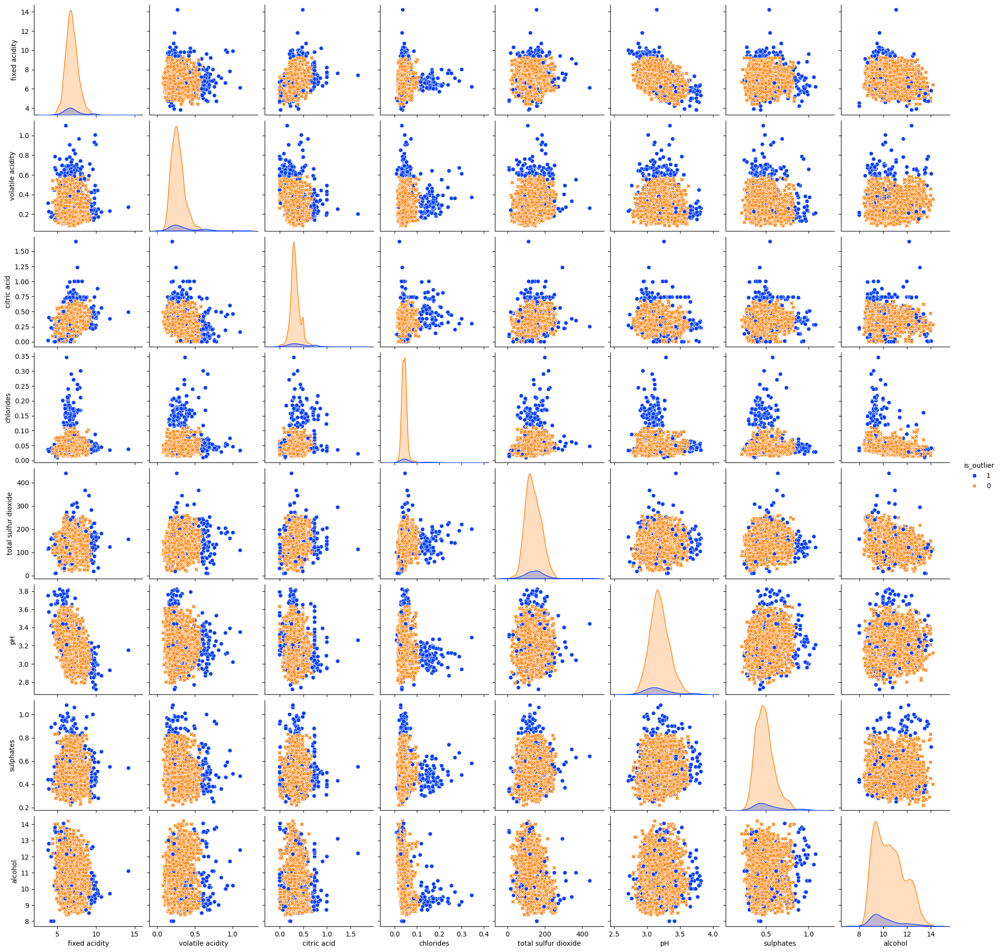

In [15]:
# ~55 сек
labeled_data = data_features.copy()
labeled_data['is_outlier'] = std_outliers

sns.pairplot(data=labeled_data, vars = other_features,
             hue='is_outlier', hue_order=[1, 0],
             markers=['X', 'o'],  palette='bright');

# Обнаружение аномалий


`Scikit-learn` имеет несколько алгоритмов обнаружения аномалий. Их описание и примеры приведены на [этой странице](https://scikit-learn.org/stable/modules/outlier_detection.html).

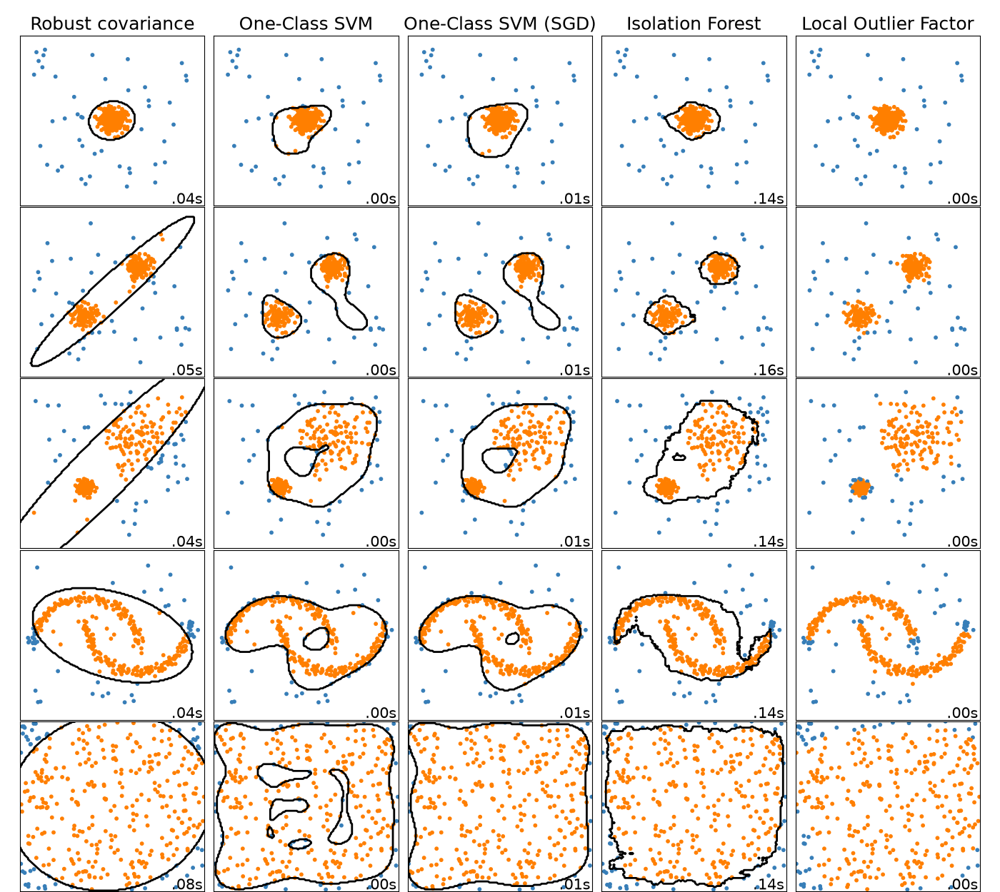


## Метод опорных векторов одного класса (One-class SVM) <a id="one-class_svm"></a>


## Кратко о методе опорных векторов (SVM)

В двух словах, SVM — это базовая линейная модель. Основная идея алгоритма (в задаче классификации) заключается в разделении классов гиперплоскостью таким образом, чтобы максимизировать расстояние (зазор) между ними. Изначально алгоритм мог работать только с линейно разделимыми классами, однако в 90-х годах прошлого века метод приобрёл особую популярность благодаря введению «Kernel Trick» (ядрового трюка) (1992), позволившего эффективно работать с линейно неразделимыми данными.

![](https://sandipanweb.files.wordpress.com/2018/04/svm_slack.png?w=676)

## Ядровой трюк (Kernel Trick)

Ядро — это функция, которая может преобразовывать пространство признаков (в том числе нелинейно), без непосредственного преобразования самих признаков.

Это крайне эффективно с точки зрения вычислений и потенциально позволяет получать бесконечномерные пространства признаков.

Идея состоит в том, что классы, которые линейно неразделимы в текущем пространстве признаков, могут стать разделимыми в пространствах более высокой размерности:

![](https://miro.medium.com/max/1838/1*eU9PzjVcLNbNEzBC2g_iWg.jpeg)

## Метод опорных векторов одного класса
Хорошая [статья](https://scikit-learn.org/stable/auto_examples/svm/plot_oneclass.html) с объяснением.

**Метод опорных векторов одного класса (One Class SVM)** — это одна из форм классического алгоритма, однако, как следует из названия, для его обучения нам нужен только один класс, пусть даже немного «зашумлённый», и мы хотим научиться определять для каждого нового наблюдения, является ли оно аномальным или нет.

**Основная идея:** преобразовать пространство признаков и провести разделяющую гиперплоскость так, чтобы наблюдения находились как можно дальше от начала координат:

![](https://www.researchgate.net/profile/Hany_Alashwal/publication/242572058/figure/fig1/AS:393295319584771@1470780319210/Classification-in-one-class-SVM.png)

В результате мы получаем границу, по одну сторону которой находятся наиболее «плотные» и похожие между собой наблюдения из обучающей выборки, а по другую — аномальные значения, не похожие на остальные. Долю таких аномальных наблюдений, которые модель будет стараться отделить от основной части выборки, мы задаём в самом начале обучения с помощью параметра `nu`


In [16]:
from sklearn.preprocessing import RobustScaler
scaler = RobustScaler()
scaled_data = pd.DataFrame(
    data=scaler.fit_transform(data_features),
    columns=data_features.columns
)

In [17]:
from sklearn.svm import OneClassSVM

one_class_svm = OneClassSVM(nu=0.10, gamma='auto')
one_class_svm.fit(scaled_data)
svm_outliers = one_class_svm.predict(scaled_data)
svm_outliers = np.array([1 if label == -1 else 0 for label in svm_outliers])

In [18]:
anomalies_report(svm_outliers)

Total number of outliers: 499
Percentage of outliers:   10.19%


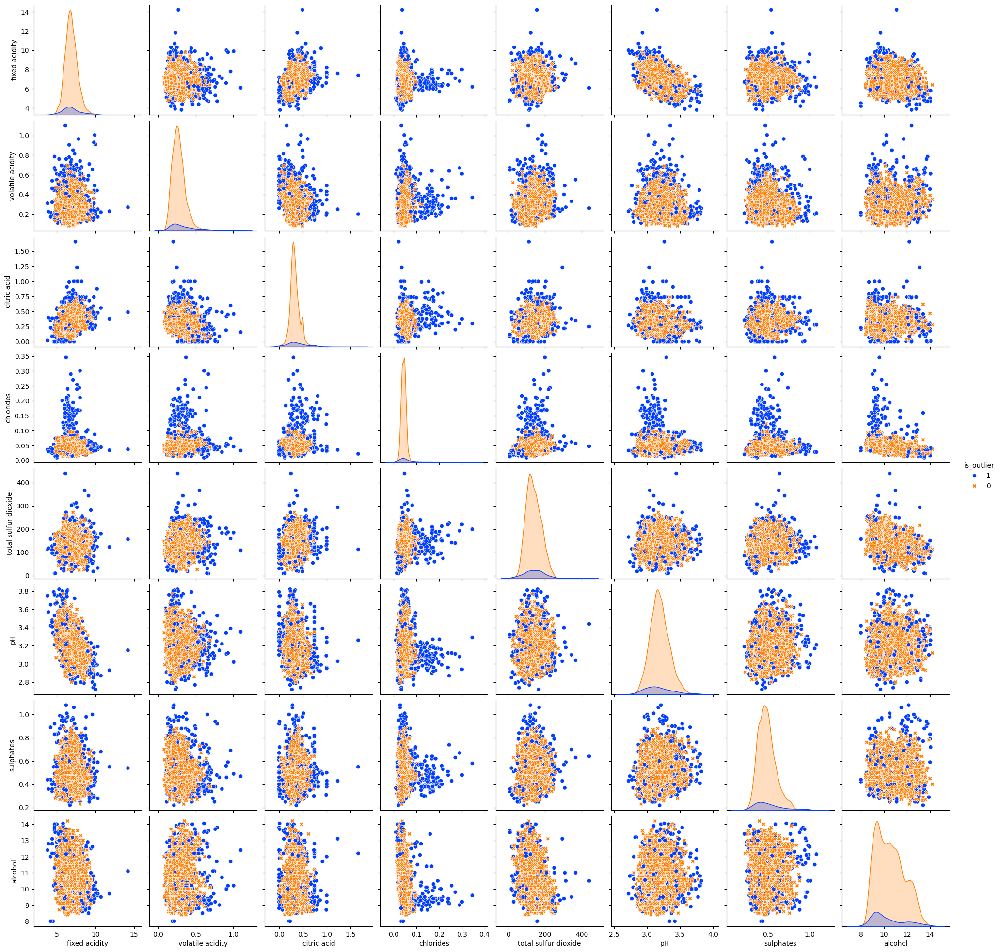

In [19]:
# ~51 сек
labeled_data = data_features.copy()
labeled_data['is_outlier'] = svm_outliers

sns.pairplot(data=labeled_data, vars = other_features,
             hue='is_outlier', hue_order=[1, 0],
             markers=['X', 'o'],  palette='bright');

## Достоинства и недостатки

\+ Благодаря ядровому трюку модель способна строить **нелинейные разделяющие границы**

\+ Особенно удобно использовать, когда в данных недостаточно «плохих» наблюдений для применения стандартного подхода обучения с учителем — бинарной классификации

\- Может сильно **переобучаться** и давать большое количество ложноотрицательных результатов, если зазор разделения слишком мал


## Изолирующий лес (Isolation Forest) <a id="isolation_forest"></a>


## <center> Изолирующий лес (Isolation Forest) </center>

Идея — посмотрим, насколько легко «изолировать» наблюдение от всех остальных. Если это слишком легко, вероятно, оно находится далеко и является выбросом. Если очень сложно — скорее всего, оно похоже на множество других точек и выбросом не является.


**Алгоритм:**
1. Выбрать точку для изоляции.
2. Для каждого признака установить диапазон изоляции между минимальным и максимальным значением.
3. Выбрать признак случайным образом.
4. Выбрать значение из диапазона случайным образом:
    - Если точка больше выбранного значения, сдвинуть минимальный диапазон признака до этого значения.
    - Если точка меньше — сдвинуть максимальное значение признака до этого значения.
5. Повторять шаги 3 и 4, пока точка не будет изолирована. То есть пока точка не окажется единственной в диапазоне по всем признакам.
6. Подсчитать количество повторений шагов 3 и 4.

Хорошая [статья](https://quantdare.com/isolation-forest-algorithm/) с объяснением.


In [20]:
from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(n_estimators=100, contamination=0.1,
                                   max_features=1.0, bootstrap=True)
isolation_forest.fit(scaled_data)

isolation_outliers = isolation_forest.predict(scaled_data)
isolation_outliers = np.array([1 if label == -1 else 0 for label in isolation_outliers])

In [21]:
anomalies_report(isolation_outliers)

Total number of outliers: 490
Percentage of outliers:   10.00%


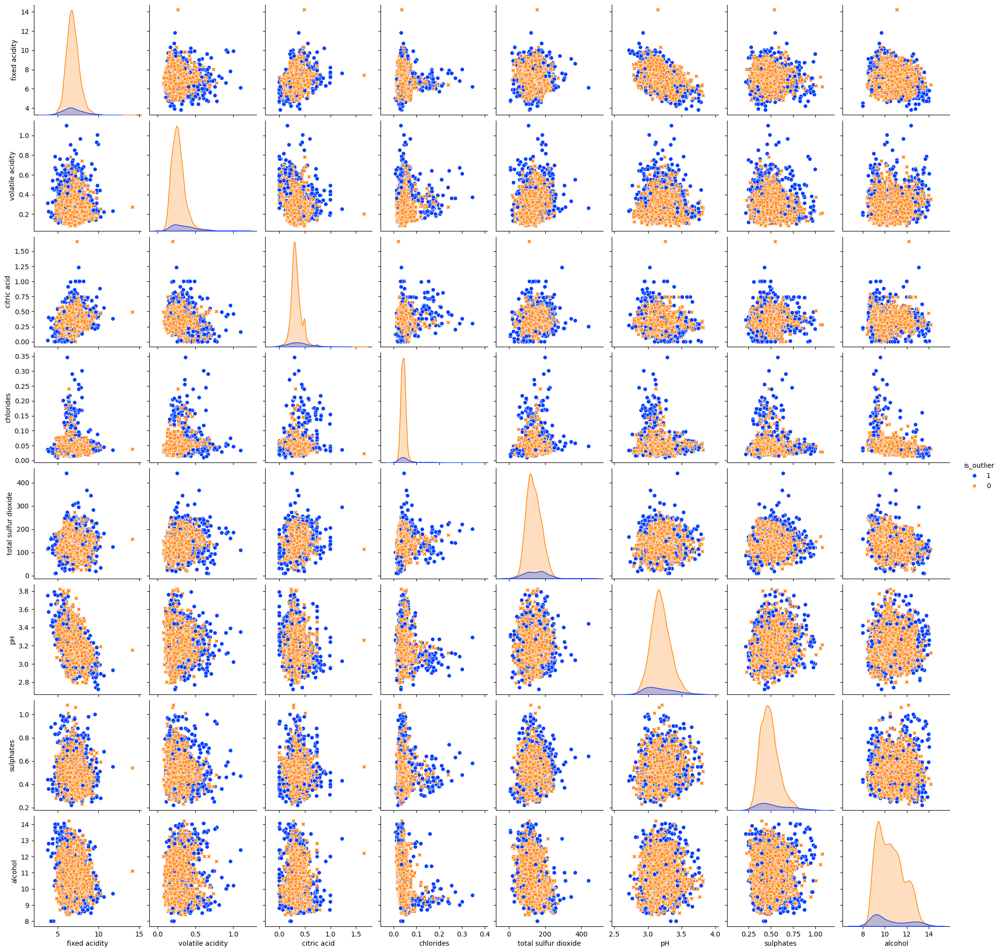

In [22]:
# ~48 сек
labeled_data = data_features.copy()
labeled_data['is_outlier'] = isolation_outliers

sns.pairplot(data=labeled_data, vars = other_features,
             hue='is_outlier', hue_order=[1, 0],
             markers=['X', 'o'],  palette='bright');

## Достоинства и недостатки

\+ **Нелинейные разделяющие границы**, интуитивно понятные принципы работы

\+ Удобно использовать, когда нельзя перейти к бинарной классификации

\- Довольно сложная настройка параметров, которую трудно провести без хотя бы минимальной разметки или предположения о количестве «загрязнённых» наблюдений — параметр `contamination`


## CUSUM <a id="cumsum"></a>


[Обнаружение изменений](http://en.wikipedia.org/wiki/Change_detection) (Change detection) относится к процедурам выявления резких изменений в каком-либо явлении (Basseville и Nikiforov, 1993; Gustafsson, 2000). Под резким изменением понимается любое отклонение от предыдущих известных данных, происходящее быстрее ожидаемого, по такой характеристике данных, как амплитуда, среднее, дисперсия, частота и т. д.

Алгоритм [кумулятивной суммы (CUSUM)](http://en.wikipedia.org/wiki/CUSUM) — классический метод мониторинга изменений. Одна из форм реализации алгоритма CUSUM предполагает вычисление кумулятивных сумм положительных и отрицательных изменений ($g_t^+$ и $g_t^-$) в данных ($x$) и сравнение с $threshold$ (порогом). При превышении порога обнаруживается изменение ($t_{talarm}$), и кумулятивная сумма сбрасывается до нуля. Чтобы избежать обнаружения изменения при его отсутствии или при медленном дрейфе, алгоритм также зависит от параметра $drift$ для коррекции. Данная форма алгоритма CUSUM задаётся следующим образом:

$$ \begin{array}{l l}
\left\{ \begin{array}{l l}
s[t] = x[t] - x[t-1] \\
g^+[t] = max\left(g^+[t-1] + s[t]-drift,\; 0\right) \\
g^-[t] = max\left(g^-[t-1] - s[t]-drift,\; 0\right)
\end{array} \right. \\
\\
\; if \;\;\; g^+[t] > threshold \;\;\; or \;\;\;  g^-[t] > threshold: \\
\\
\left\{ \begin{array}{l l}
t_{talarm}=t \\
g^+[t] = 0 \\
g^-[t] = 0
\end{array} \right.
\end{array} $$

<!-- TEASER_END -->

Существуют различные реализации алгоритма CUSUM; например, слагаемое суммы последних элементов ($s[t]$ выше) может иметь более длинную историю (с фильтрацией), может быть нормализовано путём вычитания среднего и деления на дисперсию, или это слагаемое может быть возведено в квадрат для обнаружения изменений как дисперсии, так и параметров и т. д.

Для корректной работы алгоритма CUSUM необходимо настроить параметры $h$ и $v$ в соответствии с тем, что считается изменением в данных. Согласно Gustafsson (2000), настройка может выполняться по следующим шагам:

 - Начать с очень большого $threshold$ (порога).  
 - Выбрать $drift$ равным половине ожидаемого изменения, или настроить $drift$ так, чтобы $g$ = 0 более 50% времени.  
 - Затем установить $threshold$ так, чтобы обеспечить требуемое количество ложных срабатываний (это можно сделать автоматически) или задержку обнаружения.  
 - Если требуется более быстрое обнаружение, попробовать уменьшить $drift$.  
 - Если нужно меньше ложных срабатываний, попробовать увеличить $drift$.  
 - Если часть моментов изменений не имеет смысла, попробовать увеличить $drift$.


In [23]:
!pip install detecta

Функция `detect_cusum.py` из Python-модуля `detecta` реализует алгоритм CUSUM и процедуру вычисления конца обнаруженного изменения. Сигнатура функции:   

```python
ta, tai, taf, amp = detect_cusum(x, threshold=1, drift=0, ending=False, show=True, ax=None)
```   

Посмотрим, как использовать `detect_cusum.py`; сначала импортируем необходимые библиотеки Python и настроим окружение:


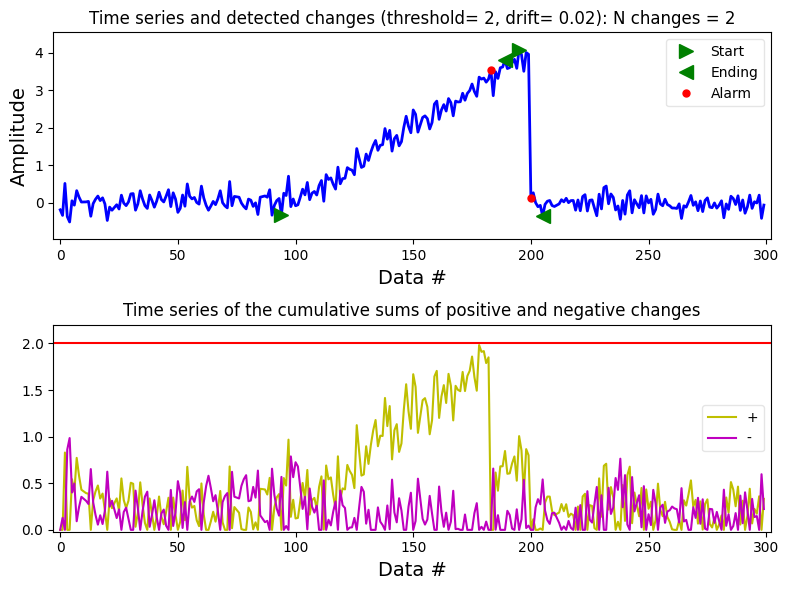

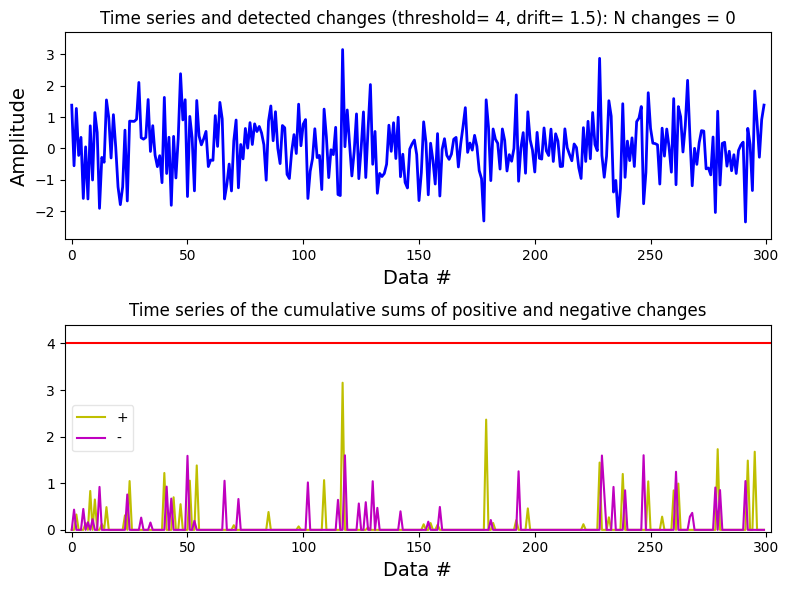

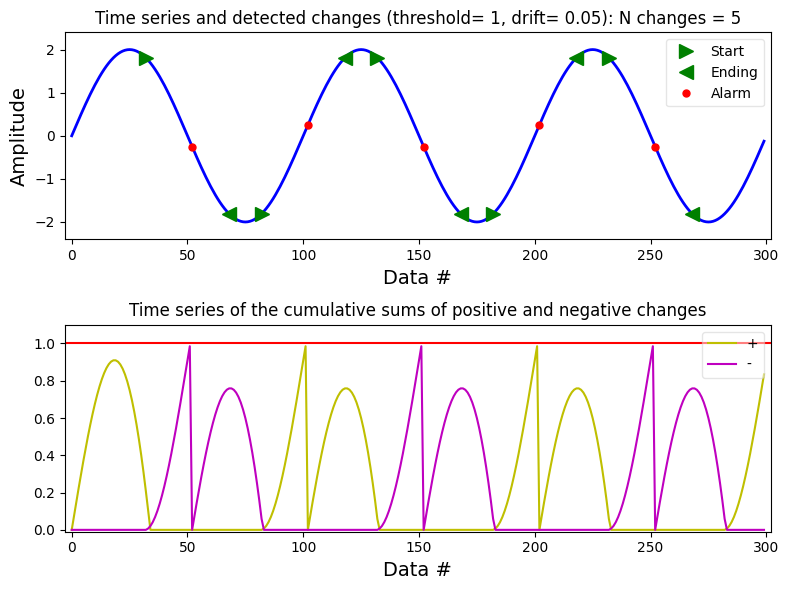

In [24]:
from detecta import detect_cusum

x = np.random.randn(300)/5
x[100:200] += np.arange(0, 4, 4/100)
ta, tai, taf, amp = detect_cusum(x, 2, .02, True, True)

x = np.random.randn(300)
detect_cusum(x, 4, 1.5, True, True)

x = 2*np.sin(2*np.pi*np.arange(0, 3, .01))
ta, tai, taf, amp = detect_cusum(x, 1, .05, True, True)

## Производительность функции

Вот простой тест производительности `detect_cusum.py`:


In [25]:
x = np.random.randn(10000)
x[400:600] += 6
print('Detection of onset (data size = %d):' %x.size)
%timeit detect_cusum(x, 4, 1.5, True, False)

Detection of onset (data size = 10000):
85.9 ms ± 25.9 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


## Ссылки

- Michèle Basseville and Igor V. Nikiforov (1993). [Detection of Abrupt Changes: Theory and Application](http://books.google.com.br/books/about/Detection_of_abrupt_changes.html?id=Vu5SAAAAMAAJ). Prentice-Hall.   
- Fredrik Gustafsson (2000) [Adaptive Filtering and Change Detection](http://books.google.com.br/books?id=cyNTAAAAMAAJ). Wiley.


# Понижение размерности

Часто признаков бывает очень много: например, чёрно-белая картинка $64 \times 64$ — это уже $4096$ признаков (яркостей пикселей), а цветная — $64 \times 64 \times 3 = 12288$ (по три канала RGB на пиксель). Многие из них сильно скоррелированы: соседние пиксели почти всегда похожи. Хочется перейти к небольшому числу **новых** признаков так, чтобы информация о данных по возможности сохранилась.

Зачем это нужно:
- **визуализация** — данные можно нарисовать в 2D;
- **сжатие** — хранить меньше чисел;
- **борьба с шумом** — отбрасываем «мелкие» компоненты, в которых в основном шум;
- **ускорение и улучшение моделей** — меньше признаков, меньше переобучения;
- **поиск аномалий** — объекты, которые плохо описываются главными компонентами, подозрительны (связь с первой частью семинара!).

Ниже разберём метод главных компонент (PCA) и сингулярное разложение (SVD), через которое PCA на практике и считается.

## Метод главных компонент (PCA) <a id="pca"></a>

Пусть $X \in \mathbb{R}^{N \times D}$ — матрица «объекты–признаки», **в которой среднее каждого признака равно нулю** (данные центрированы), а $w$ — единичный вектор. Тогда $Xw$ — это проекции всех объектов на направление $w$. Ищем направление, вдоль которого разброс (дисперсия) проекций максимален:

$$
\max_{w:\ \|w\|=1} \|Xw\|^2 = \max_{w:\ \|w\|=1} w^T X^T X w .
$$

Решение — собственный вектор матрицы $X^T X$ (с точностью до множителя $\frac{1}{N}$ это ковариационная матрица) с наибольшим собственным значением. Это **первая главная компонента**. Вторая — направление максимальной дисперсии среди ортогональных первой, и так далее.

Итог: главные компоненты — это новый ортонормированный базис, упорядоченный по убыванию объяснённой дисперсии. Оставляя первые $k$ компонент, мы получаем лучшее (в смысле среднеквадратичной ошибки) линейное приближение данных в $k$-мерном подпространстве.

### PCA на плоскости

Сгенерируем выборку из двумерного нормального распределения, у которого дисперсия по первой оси больше, чем по второй, и проверим, найдёт ли PCA это направление.

В `sklearn` после обучения в `components_` лежат главные направления (единичные векторы), а в `explained_variance_` — дисперсия вдоль каждого из них. Нарисуем направления стрелками, длина которых пропорциональна дисперсии.

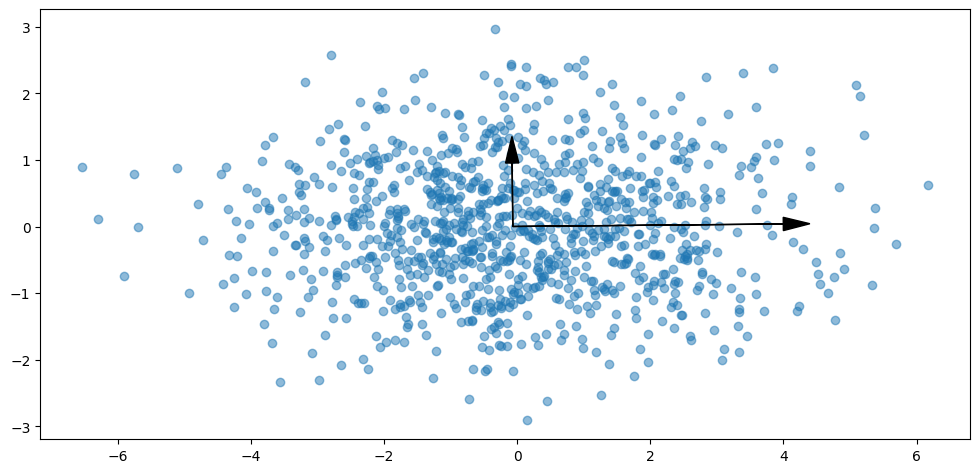

In [26]:
from sklearn.decomposition import PCA

np.random.seed(314512)
data_synth_1 = np.random.multivariate_normal(
    mean=[0, 0],
    cov=[[4, 0],
         [0, 1]],
    size=1000
)

def PCA_show(dataset):
    plt.scatter(*zip(*dataset), alpha=0.5)

    dec = PCA()
    dec.fit(dataset)
    ax = plt.gca()
    for comp_ind in range(dec.components_.shape[0]):
        component = dec.components_[comp_ind, :]
        var = dec.explained_variance_[comp_ind]
        start, end = dec.mean_, component * var
        ax.arrow(start[0], start[1], end[0], end[1],
                 head_width=0.2, head_length=0.4, fc='k', ec='k')
    ax.set_aspect('equal', adjustable='box')

plt.figure(figsize=(12, 6))
PCA_show(data_synth_1)

PCA всё нашёл правильно — но здесь это можно было сделать, просто посчитав дисперсию каждого признака. Повернём данные на фиксированный угол и убедимся, что PCA находит повёрнутые направления.

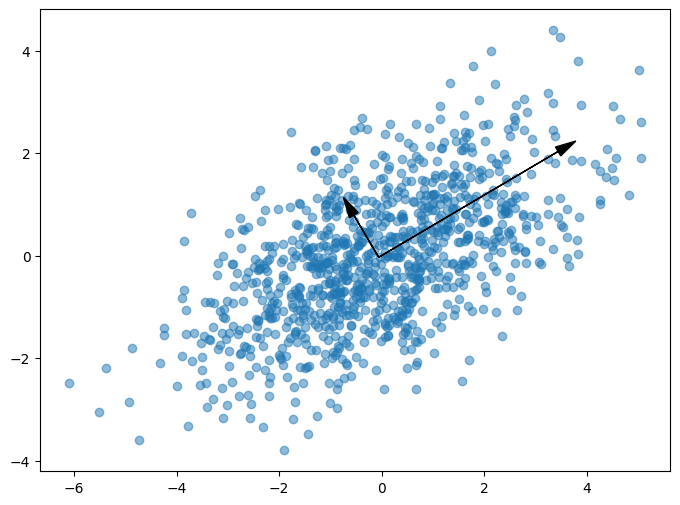

In [27]:
angle = np.pi / 6
rotate = np.array([
    [np.cos(angle), -np.sin(angle)],
    [np.sin(angle),  np.cos(angle)],
])
data_synth_2 = rotate.dot(data_synth_1.T).T  # поворачиваем каждую точку

plt.figure(figsize=(12, 6))
PCA_show(data_synth_2)

А вот примеры, где найденные направления не дают хороших признаков.

**Упражнение:** объясните, почему так произошло.

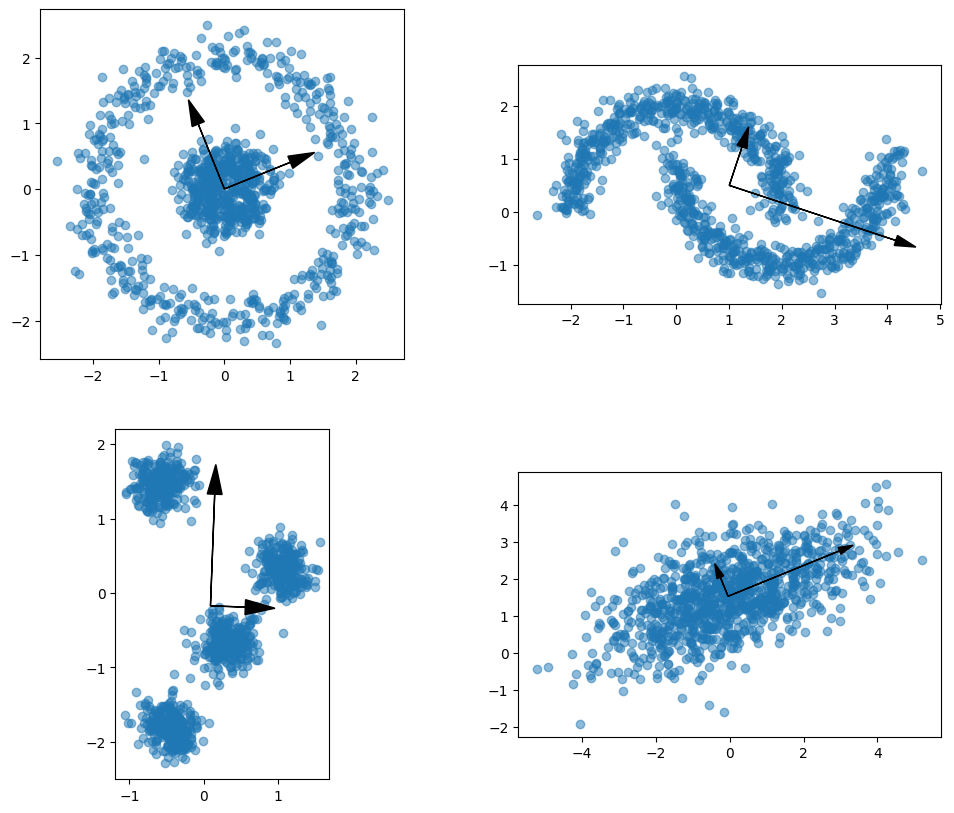

In [28]:
from sklearn.datasets import make_circles, make_moons, make_blobs

np.random.seed(54242)
data_synth_bad = [
    make_circles(n_samples=1000, factor=0.2, noise=0.1)[0] * 2,
    make_moons(n_samples=1000, noise=0.1)[0] * 2,
    make_blobs(n_samples=1000, n_features=2, centers=4)[0] / 5,
    np.random.multivariate_normal(mean=[0, 1.5], cov=[[3, 1], [1, 1]], size=1000),
]

plt.figure(figsize=(12, 10))
for i, data in enumerate(data_synth_bad):
    plt.subplot(2, 2, i + 1)
    PCA_show(data)

<details>
<summary>Подсказка</summary>

PCA ищет только **линейные** направления максимальной дисперсии. Кольца и полумесяцы — нелинейные структуры; у кругов дисперсия одинакова во всех направлениях, и выделенного направления просто нет. Наконец, большая дисперсия не обязана означать «полезность» признака для задачи.
</details>

## Сингулярное разложение (SVD) <a id="svd"></a>

Любую матрицу $X \in \mathbb{R}^{N \times D}$ можно представить в виде

$$
X = U \Sigma V^T,
$$

где
- $U \in \mathbb{R}^{N \times N}$ и $V \in \mathbb{R}^{D \times D}$ — ортогональные матрицы (их столбцы — левые и правые **сингулярные векторы**);
- $\Sigma$ — диагональная матрица с неотрицательными **сингулярными числами** $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$.

**Геометрический смысл.** Любое линейное преобразование раскладывается в три шага: поворот ($V^T$) → растяжение вдоль осей ($\Sigma$) → ещё один поворот ($U$). Подробно и с картинками: [Singular Value Decomposition as Simply as Possible](https://gregorygundersen.com/blog/2018/12/10/svd/).

**Удобная запись — сумма матриц ранга 1:**

$$
X = \sum_{i=1}^{r} \sigma_i\, u_i v_i^T .
$$

Каждое слагаемое — «слой» матрицы, а $\sigma_i$ — его вес. Если оставить только первые $k$ слагаемых, получится **лучшее приближение матрицы $X$ матрицей ранга $k$** (теорема Эккарта–Янга). На этом построены и PCA, и сжатие картинок ниже.

### Связь SVD и PCA

Если $X$ центрирована, то

$$
X^T X = V \Sigma U^T U \Sigma V^T = V \Sigma^2 V^T .
$$

То есть:
- столбцы $V$ (строки $V^T$) — собственные векторы $X^TX$, то есть **главные компоненты**;
- дисперсия вдоль $i$-й компоненты равна $\frac{\sigma_i^2}{N-1}$;
- координаты объектов в новом базисе: $XV = U\Sigma$.

Почему считают через SVD, а не через собственные векторы $X^TX$: явно строить $X^TX$ дорого (матрица $D \times D$) и численно неустойчиво (числа обусловленности возводятся в квадрат). Для SVD есть эффективные и устойчивые алгоритмы, в том числе [рандомизированный усечённый SVD](https://arxiv.org/abs/0909.4061), который считает только первые $k$ компонент. `sklearn.decomposition.PCA` внутри использует именно SVD.

Проверим связь на практике.

In [29]:
X_demo = data_synth_2 - data_synth_2.mean(axis=0)   # центрируем данные!

# full_matrices=False — "экономная" версия: U имеет размер N x D, а не N x N
U, S, Vt = np.linalg.svd(X_demo, full_matrices=False)

pca_demo = PCA().fit(data_synth_2)

print('Строки Vt (SVD):\n', Vt)
print('Главные компоненты (PCA):\n', pca_demo.components_)
print('sigma^2 / (N-1):      ', S**2 / (len(X_demo) - 1))
print('explained_variance_:  ', pca_demo.explained_variance_)

Строки Vt (SVD):
 [[-0.86135356 -0.50800594]
 [ 0.50800594 -0.86135356]]
Главные компоненты (PCA):
 [[ 0.86135356  0.50800594]
 [-0.50800594  0.86135356]]
sigma^2 / (N-1):       [4.06379269 0.95373144]
explained_variance_:   [4.06379269 0.95373144]


Компоненты совпадают с точностью до знака: если $v$ — сингулярный вектор, то и $-v$ тоже, поэтому знак у разных реализаций может отличаться.

## SVD на лицах: «собственные лица» <a id="eigenfaces"></a>

Теперь самое интересное. Возьмём датасет [Olivetti faces](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_olivetti_faces.html): 400 чёрно-белых фотографий 40 людей (по 10 фото на каждого), размер $64 \times 64$. Каждую картинку вытянем в вектор длины $4096$ — получим матрицу $X$ размера $400 \times 4096$.

План:
1. Найдём **среднее лицо**.
2. Вычтем его из всех лиц — останутся только «отличия от среднего».
3. Сделаем SVD и посмотрим на главные компоненты — **собственные лица** (eigenfaces).
4. Восстановим лица по небольшому числу компонент.
5. Разберёмся, что «означают» отдельные компоненты.
6. Нарисуем все лица на плоскости.
7. Используем ошибку восстановления как детектор аномалий.

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
(400, 4096)


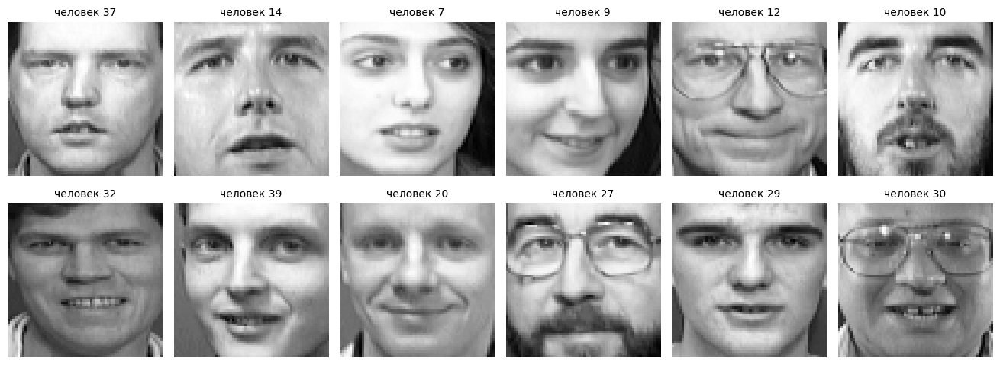

In [30]:
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces(shuffle=True, random_state=432542)
X_faces = faces.data          # матрица 400 x 4096, яркости в [0, 1]
y_faces = faces.target        # номер человека (0..39)
image_shape = (64, 64)

print(X_faces.shape)

def show_faces(images, titles=None, rows=2, cols=6, size=2.2, cmap='gray'):
    # Рисует набор картинок-векторов сеткой rows x cols
    plt.figure(figsize=(cols * size, rows * size * 1.15))
    for i in range(min(len(images), rows * cols)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(images[i].reshape(image_shape), cmap=cmap)
        if titles is not None:
            plt.title(titles[i], fontsize=10)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

show_faces(X_faces[:12], titles=[f'человек {t}' for t in y_faces[:12]])

### Шаг 1. Среднее лицо

Усредним все 400 фотографий попиксельно.

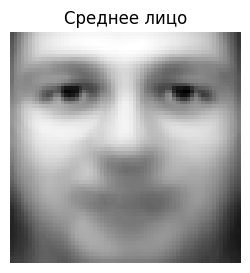

In [31]:
mean_face = X_faces.mean(axis=0)

plt.figure(figsize=(3, 3))
plt.imshow(mean_face.reshape(image_shape), cmap='gray')
plt.title('Среднее лицо')
plt.axis('off')
plt.show()

Получился размытый, но вполне узнаваемый «усреднённый человек»: глаза, нос и рот у всех примерно на одних местах, поэтому они не размываются.

### Шаг 2. Вычитаем среднее

Теперь из каждого лица попиксельно вычтем среднее лицо. Для PCA это обязательный шаг: метод ищет направления разброса **вокруг центра** данных, поэтому центр нужно перенести в ноль.

После вычитания в каждом пикселе остаётся число, которое показывает, насколько этот пиксель ярче или темнее, чем у среднего лица. Такие числа бывают и отрицательными, поэтому рисуем их в оттенках серого так, чтобы ноль был серединой шкалы:
- **средне-серый** — пиксель такой же, как у среднего лица (разность около нуля);
- **светлее серого** — здесь фото ярче среднего (например, освещённая щека или светлый фон);
- **темнее серого** — здесь фото темнее среднего (например, тень, тёмные волосы, оправа очков).

Видно, что от лица «остаются» в основном индивидуальные черты и особенности освещения: именно этот разброс PCA и будет раскладывать на компоненты.

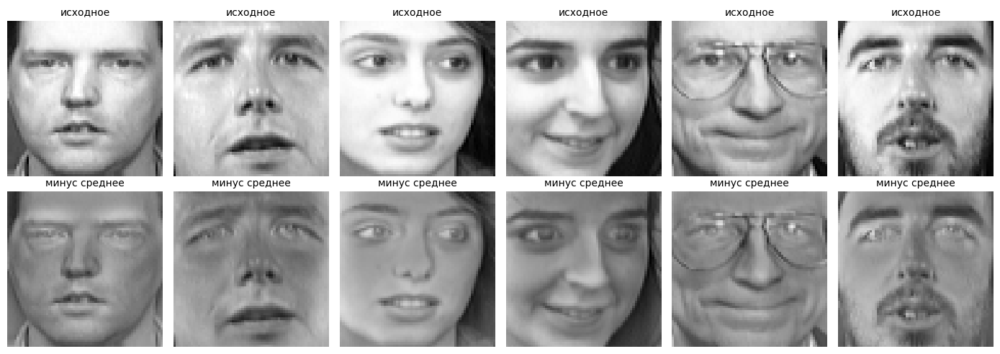

In [32]:
X_centered = X_faces - mean_face

# Разности бывают отрицательными: задаём симметричную шкалу [-lim, lim],
# чтобы ноль ("как у среднего") отображался средне-серым цветом
lim = np.abs(X_centered[:6]).max()
plt.figure(figsize=(14, 5))
for i in range(6):
    plt.subplot(2, 6, i + 1)
    plt.imshow(X_faces[i].reshape(image_shape), cmap='gray')
    plt.title('исходное', fontsize=10); plt.axis('off')
    plt.subplot(2, 6, i + 7)
    plt.imshow(X_centered[i].reshape(image_shape), cmap='gray', vmin=-lim, vmax=lim)
    plt.title('минус среднее', fontsize=10); plt.axis('off')
plt.tight_layout()
plt.show()

### Шаг 3. SVD и собственные лица

Разложим центрированную матрицу $X_{centered}$ (400 × 4096) в SVD:

$$
X_{centered} = U \Sigma V^T .
$$

Что означает каждый множитель на языке лиц:
- **$V^T$ (400 × 4096)**: каждая строка — вектор длины 4096, то есть её можно нарисовать как картинку $64 \times 64$. Это **собственные лица** (eigenfaces), «базисные» отклонения от среднего;
- **$\Sigma$ (400 сингулярных чисел)** — насколько важен каждый базисный элемент;
- **$U \Sigma$ (400 × 400)**: строка $i$ — «рецепт» лица $i$, то есть с какими коэффициентами смешать собственные лица, чтобы получить это фото.

Строки $V^T$ — это ровно главные компоненты PCA (мы проверили это выше на двумерном примере). То есть «собственные лица» — это одновременно PCA и SVD: **PCA — это задача** (найти направления максимальной дисперсии), **SVD — инструмент**, которым её решают. Ниже мы работаем напрямую с матрицами $U$, $\Sigma$, $V^T$, без `sklearn.PCA`.

In [33]:
%%time
U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
print(U.shape, S.shape, Vt.shape)

(400, 400) (400,) (400, 4096)
CPU times: user 1.89 s, sys: 47.3 ms, total: 1.94 s
Wall time: 2 s


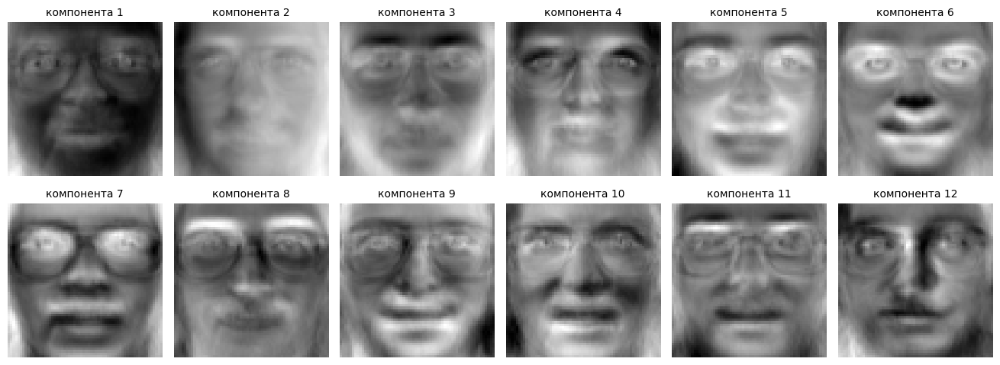

In [34]:
show_faces(Vt[:12], titles=[f'компонента {i + 1}' for i in range(12)])  # серый цвет, как и у самих лиц

Выглядит жутковато, но в этом есть смысл. Первые компоненты обычно отвечают за самые «грубые» источники разброса — освещение (слева/справа, сверху/снизу), общую яркость, поворот головы. Дальше идут более тонкие детали: очки, борода, форма носа и бровей.

**Вопрос:** почему у собственных лиц нет «правильного» цвета (они могут быть и светлыми, и тёмными в одном месте)?

### А если не вычитать среднее?

Разница между «просто SVD» и PCA — только в центрировании. Сделаем SVD **исходной** матрицы лиц, без вычитания среднего, и посмотрим на первый правый сингулярный вектор.

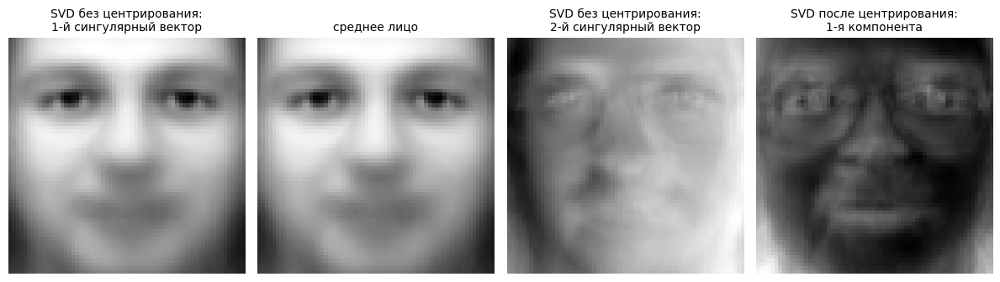

Косинус угла между 1-м сингулярным вектором и средним лицом: 1.0000
Первые сингулярные числа без центрирования: [717.2  67.5  50.5  40.2]


In [35]:
U_raw, S_raw, Vt_raw = np.linalg.svd(X_faces, full_matrices=False)

v1 = Vt_raw[0] * np.sign(Vt_raw[0].sum())   # знак сингулярного вектора произволен — делаем его "положительным"

plt.figure(figsize=(12, 3.5))
for j, (img, title) in enumerate([
    (v1, 'SVD без центрирования:\n1-й сингулярный вектор'),
    (mean_face, 'среднее лицо'),
    (Vt_raw[1], 'SVD без центрирования:\n2-й сингулярный вектор'),
    (Vt[0], 'SVD после центрирования:\n1-я компонента'),
]):
    plt.subplot(1, 4, j + 1)
    plt.imshow(img.reshape(image_shape), cmap='gray')
    plt.title(title, fontsize=10)
    plt.axis('off')
plt.tight_layout()
plt.show()

cos = v1 @ mean_face / np.linalg.norm(mean_face)
print(f'Косинус угла между 1-м сингулярным вектором и средним лицом: {cos:.4f}')
print(f'Первые сингулярные числа без центрирования: {np.round(S_raw[:4], 1)}')

Первый сингулярный вектор нецентрированной матрицы практически совпадает со средним лицом, а первое сингулярное число намного больше остальных. SVD «тратит» первую компоненту на то, что все картинки — это лица, расположенные далеко от нуля. Это неинтересно: все лица похожи друг на друга.

Поэтому для PCA среднее вычитают заранее, и тогда первая компонента описывает уже главное **различие** между лицами. Без центрирования SVD тоже работает: это наилучшее приближение матрицы низкого ранга. Такой вариант называют **TruncatedSVD** (в `sklearn` это отдельный класс), его применяют, например, к разреженным матрицам текстов, где вычитать среднее нельзя.

### Сколько компонент нужно?

Посмотрим на сингулярные числа и на долю объяснённой дисперсии $\dfrac{\sum_{i \le k} \sigma_i^2}{\sum_i \sigma_i^2}$.

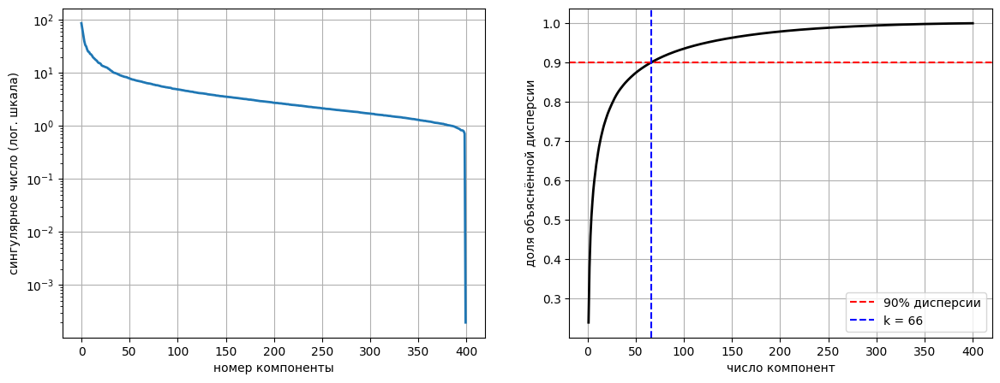

Для 90% дисперсии нужно 66 компонент из 4096 исходных признаков


In [36]:
explained = S**2 / np.sum(S**2)
cum_explained = np.cumsum(explained)
k90 = np.searchsorted(cum_explained, 0.9) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(S, lw=2)
axes[0].set_yscale('log')
axes[0].set_xlabel('номер компоненты')
axes[0].set_ylabel('сингулярное число (лог. шкала)')
axes[0].grid()

axes[1].plot(np.arange(1, len(S) + 1), cum_explained, lw=2, color='k')
axes[1].axhline(0.9, c='r', ls='--', label='90% дисперсии')
axes[1].axvline(k90, c='b', ls='--', label=f'k = {k90}')
axes[1].set_xlabel('число компонент')
axes[1].set_ylabel('доля объяснённой дисперсии')
axes[1].legend()
axes[1].grid()
plt.show()

print(f'Для 90% дисперсии нужно {k90} компонент из {X_faces.shape[1]} исходных признаков')

Сингулярные числа быстро падают: основная информация сосредоточена в первых нескольких десятках компонент. Компонент не больше 400 — по числу объектов (точнее, ранг центрированной матрицы не больше $N-1 = 399$).

### Шаг 4. Восстанавливаем лицо по $k$ компонентам

Любое лицо можно записать как

$$
\text{лицо} = \text{среднее лицо} + c_1 \cdot v_1 + c_2 \cdot v_2 + \dots + c_k \cdot v_k ,
$$

где $v_i$ — собственные лица (строки $V^T$), а коэффициенты $c_i = u_i \sigma_i$ берутся из $U\Sigma$. В матричном виде это **усечённое SVD**: $X_{centered} \approx U_k \Sigma_k V_k^T$, наилучшее приближение ранга $k$. Вместо 4096 пикселей на лицо храним $k$ чисел (плюс общие для всех $k$ собственных лиц).

Посмотрим, как лицо «проявляется» по мере добавления компонент.

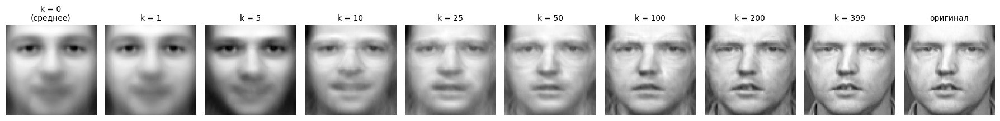

In [37]:
def reconstruct(i, k):
    # Восстанавливает лицо номер i по первым k слоям SVD:
    # X_centered[i] ≈ сумма по j<k от U[i, j] * S[j] * Vt[j]
    return mean_face + (U[i, :k] * S[:k]) @ Vt[:k]

face_idx = 0
ks = [0, 1, 5, 10, 25, 50, 100, 200, 399]
images = [reconstruct(face_idx, k) for k in ks] + [X_faces[face_idx]]
titles = ['k = 0\n(среднее)'] + [f'k = {k}' for k in ks[1:]] + ['оригинал']
show_faces(images, titles, rows=1, cols=len(images), size=1.8)

Уже при 25–50 компонентах человек узнаётся, хотя мы храним в ~100 раз меньше чисел. Проверим на нескольких лицах сразу.

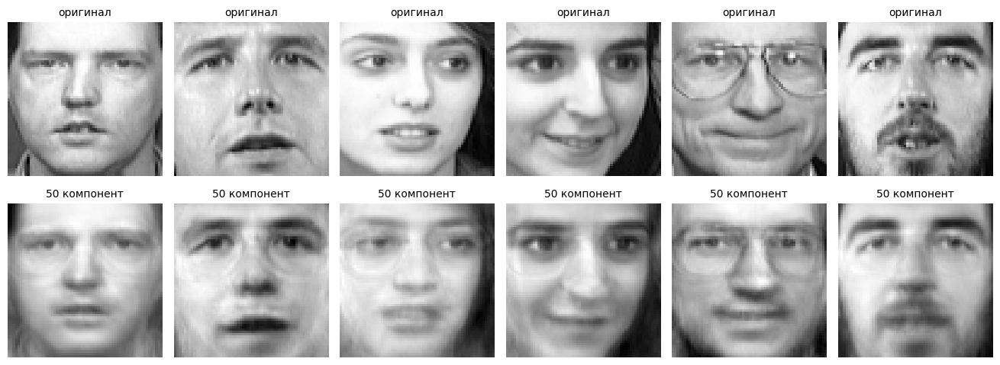

In [38]:
k = 50
idx = range(6)
images = [X_faces[i] for i in idx] + [reconstruct(i, k) for i in idx]
titles = ['оригинал'] * 6 + [f'{k} компонент'] * 6
show_faces(images, titles, rows=2, cols=6)

### Шаг 5. Что означает компонента? Двигаемся вдоль неё

Возьмём среднее лицо и будем прибавлять к нему $i$-ю компоненту с разными коэффициентами:

$$
\text{среднее лицо} + \alpha \cdot \sigma^{std}_i \cdot v_i, \quad \alpha \in [-3, 3],
$$

где $\sigma^{std}_i$ — стандартное отклонение координат вдоль $i$-й компоненты. Так видно, какой «ползунок» отвечает за какой признак лица.

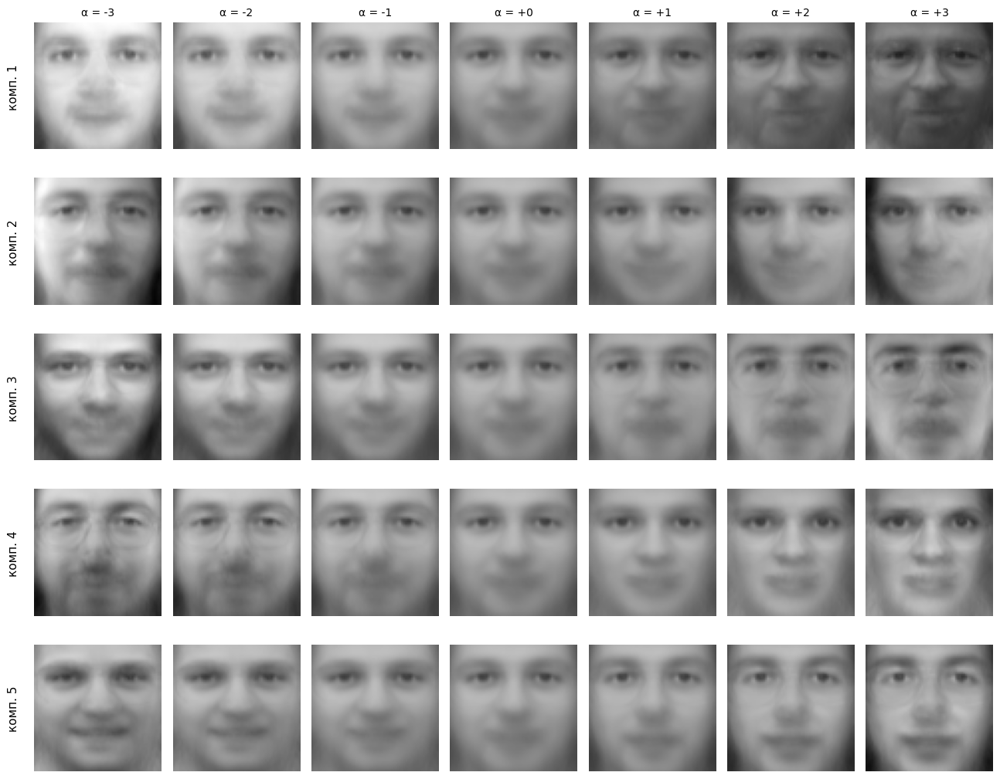

In [39]:
coords_all = X_centered @ Vt.T          # координаты всех лиц в базисе компонент (= U * S)
alphas = np.linspace(-3, 3, 7)

n_comp_to_show = 5
plt.figure(figsize=(13, 2.1 * n_comp_to_show))
for c in range(n_comp_to_show):
    std_c = coords_all[:, c].std()
    for j, a in enumerate(alphas):
        plt.subplot(n_comp_to_show, len(alphas), c * len(alphas) + j + 1)
        img = mean_face + a * std_c * Vt[c]
        plt.imshow(img.reshape(image_shape), cmap='gray', vmin=0, vmax=1)
        plt.axis('off')
        if c == 0:
            plt.title(f'α = {a:+.0f}', fontsize=10)
        if j == 0:
            plt.text(-8, 32, f'комп. {c + 1}', rotation=90, va='center', ha='right', fontsize=11)
plt.tight_layout()
plt.show()

**Задание:** попробуйте словами описать, за что отвечает каждая из первых пяти компонент (освещение? поворот головы? улыбка? очки?). Поменяйте `n_comp_to_show` и посмотрите на более далёкие компоненты.

### Шаг 6. Все лица на плоскости

Оставим только первые две координаты и нарисуем каждое лицо маленькой картинкой в точке $(c_1, c_2)$. Похожие по освещению и позе фотографии окажутся рядом.

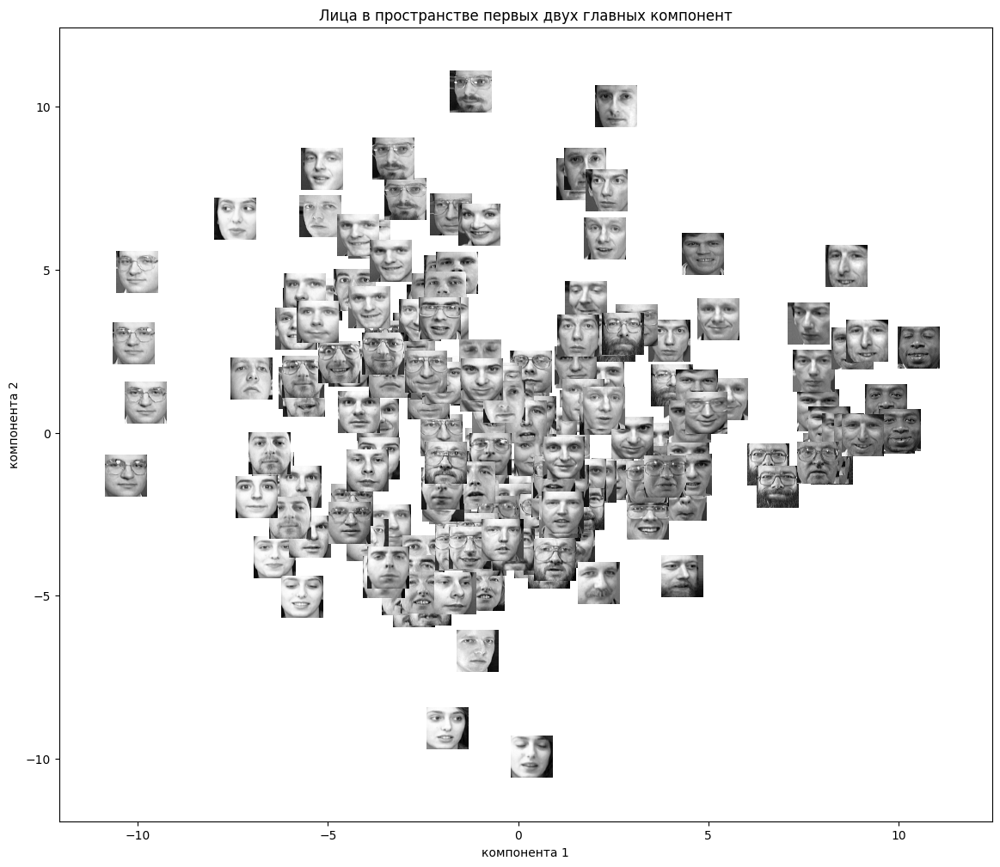

In [40]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

fig, ax = plt.subplots(figsize=(14, 12))
ax.scatter(coords_all[:, 0], coords_all[:, 1], s=0)  # невидимые точки, чтобы задать масштаб осей

for i in range(0, len(X_faces), 2):   # каждое второе лицо, чтобы не было каши
    thumb = OffsetImage(X_faces[i].reshape(image_shape), cmap='gray', zoom=0.55)
    ax.add_artist(AnnotationBbox(thumb, (coords_all[i, 0], coords_all[i, 1]), frameon=False))

ax.set_xlabel('компонента 1')
ax.set_ylabel('компонента 2')
ax.set_title('Лица в пространстве первых двух главных компонент')
plt.show()

А теперь раскрасим точки по номеру человека. Видно, что две компоненты отражают в основном условия съёмки, а не личность: фото одного человека не собираются в компактные группы. Для различения людей нужно больше компонент.

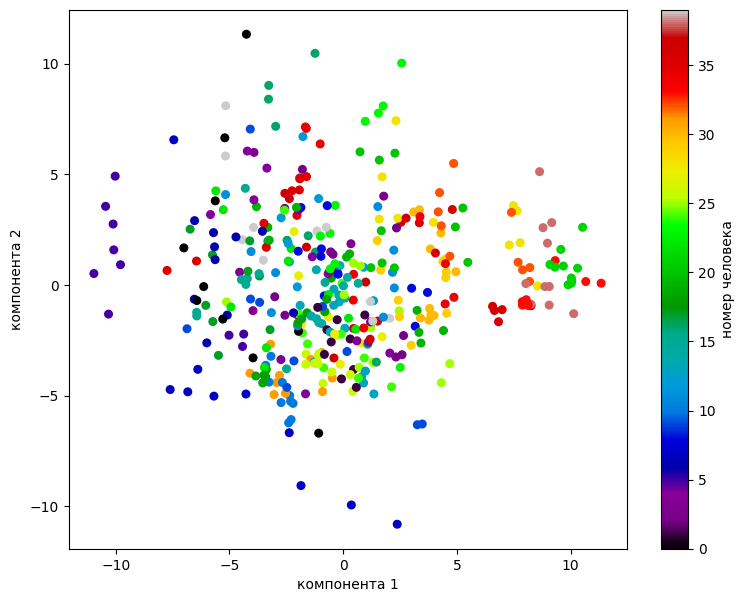

In [41]:
plt.figure(figsize=(9, 7))
plt.scatter(coords_all[:, 0], coords_all[:, 1], c=y_faces, cmap='nipy_spectral', s=30)
plt.colorbar(label='номер человека')
plt.xlabel('компонента 1')
plt.ylabel('компонента 2')
plt.show()

### Есть ли польза для моделей?

Сравним качество классификации людей (40 классов) на исходных 4096 пикселях и на первых $k$ главных компонентах. Важно: PCA обучаем только на обучающей части, поэтому собираем всё в `Pipeline`.

In [42]:
# ~2 минуты
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
import time

for name, model in [
    ('пиксели (4096)', LogisticRegression(max_iter=2000)),
    ('PCA, 20 компонент', make_pipeline(PCA(n_components=20), LogisticRegression(max_iter=2000))),
    ('PCA, 50 компонент', make_pipeline(PCA(n_components=50), LogisticRegression(max_iter=2000))),
    ('PCA, 100 компонент', make_pipeline(PCA(n_components=100), LogisticRegression(max_iter=2000))),
]:
    start = time.time()
    score = cross_val_score(model, X_faces, y_faces, cv=5).mean()
    print(f'{name:22s} accuracy = {score:.3f}   время = {time.time() - start:.1f} c')

пиксели (4096)         accuracy = 0.980   время = 143.1 c
PCA, 20 компонент      accuracy = 0.957   время = 1.6 c
PCA, 50 компонент      accuracy = 0.978   время = 2.4 c
PCA, 100 компонент     accuracy = 0.978   время = 6.2 c


Качество на нескольких десятках компонент сопоставимо с качеством на всех пикселях, а признаков в десятки раз меньше.

### Шаг 7. SVD как детектор аномалий

Свяжем с первой частью семинара. Собственные лица хорошо описывают **лица**. Если подать на вход что-то другое, восстановить его по первым $k$ компонентам не получится, и **ошибка восстановления** будет большой:

$$
\text{score}(x) = \| x - \hat{x}_k \|^2 .
$$

Это популярный способ искать аномалии: объект «не похож» на обучающие данные, если он плохо ложится в подпространство главных компонент.

Обучим «базис» на 350 лицах, а проверять будем на 50 отложенных лицах и на нескольких «странных» картинках: шум, лицо вверх ногами, лицо с засветом, кусок фотографии.

Средняя ошибка на обучающих лицах:      9.7
Средняя ошибка на новых лицах:         14.5
Порог (95-й перцентиль обучения):      15.2

обычное лицо    ошибка =     12.4     0.9× от средней   -> норма
шум             ошибка =    339.8    23.5× от средней   -> АНОМАЛИЯ
вверх ногами    ошибка =     31.4     2.2× от средней   -> АНОМАЛИЯ
засвет          ошибка =     28.8     2.0× от средней   -> АНОМАЛИЯ
здание          ошибка =    125.0     8.6× от средней   -> АНОМАЛИЯ


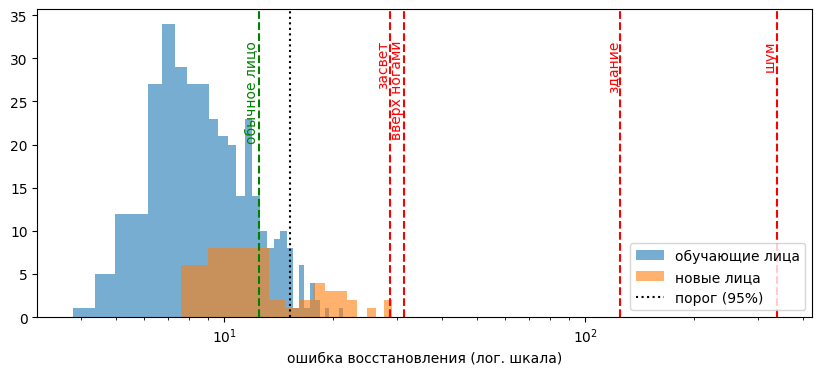

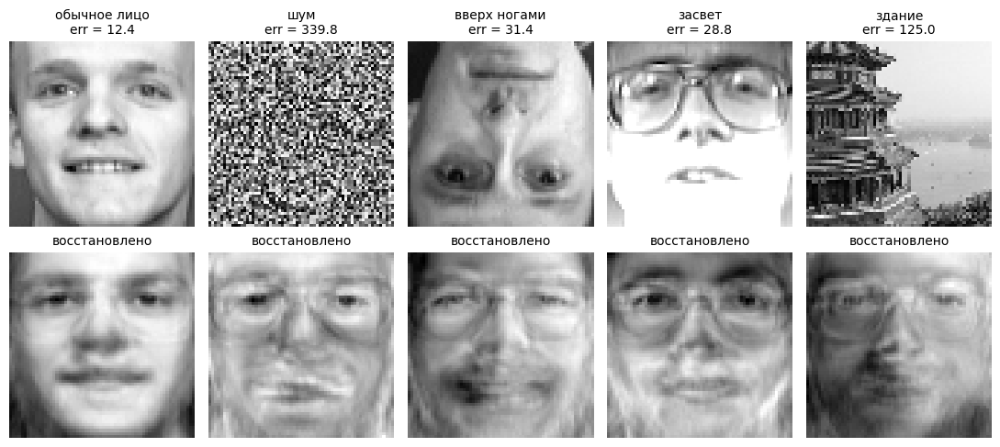

In [43]:
from sklearn.datasets import load_sample_image

X_train_f, X_test_f = X_faces[:350], X_faces[350:]
k = 50

pca_faces = PCA(n_components=k).fit(X_train_f)

def recon_error(X):
    # Ошибка восстановления: сумма квадратов разностей между картинкой и её восстановлением по k компонентам
    X_rec = pca_faces.inverse_transform(pca_faces.transform(X))
    return ((X - X_rec) ** 2).sum(axis=1)

# Готовим картинки размера 64x64: одно обычное лицо для сравнения + "аномальные"
rng = np.random.default_rng(0)
normal_face = X_test_f[2]                                     # обычное лицо, которого не было в обучении
noise = rng.uniform(0, 1, size=4096)
upside_down = X_test_f[0].reshape(image_shape)[::-1].ravel()
overexposed = np.clip(X_test_f[1] + np.linspace(0, 0.8, 4096), 0, 1)  # засвет, усиливающийся книзу
photo = load_sample_image('china.jpg').mean(axis=2)          # ч/б фото здания
photo = photo[100:356:4, 200:456:4] / 255                     # вырезаем и уменьшаем до 64x64

examples = np.vstack([normal_face, noise, upside_down, overexposed, photo.ravel()])
example_names = ['обычное лицо', 'шум', 'вверх ногами', 'засвет', 'здание']

err_train = recon_error(X_train_f)
err_test = recon_error(X_test_f)
err_examples = recon_error(examples)

# Порог: ошибка, которую превышают только 5% обучающих лиц
threshold = np.percentile(err_train, 95)

# Выводим ошибки численно
print(f'Средняя ошибка на обучающих лицах: {err_train.mean():8.1f}')
print(f'Средняя ошибка на новых лицах:     {err_test.mean():8.1f}')
print(f'Порог (95-й перцентиль обучения):  {threshold:8.1f}\n')
for name, e in zip(example_names, err_examples):
    verdict = 'АНОМАЛИЯ' if e > threshold else 'норма'
    print(f'{name:15s} ошибка = {e:8.1f}   {e / err_test.mean():5.1f}× от средней   -> {verdict}')

# Гистограмма ошибок и положение наших примеров
plt.figure(figsize=(10, 4))
plt.hist(err_train, bins=30, alpha=0.6, label='обучающие лица')
plt.hist(err_test, bins=15, alpha=0.6, label='новые лица')
plt.axvline(threshold, c='k', ls=':', label='порог (95%)')
for e, name in zip(err_examples, example_names):
    color = 'g' if name == 'обычное лицо' else 'r'
    plt.axvline(e, c=color, ls='--')
    plt.text(e, plt.ylim()[1] * 0.9, name, rotation=90, va='top', ha='right', color=color)
plt.xscale('log')
plt.xlabel('ошибка восстановления (лог. шкала)')
plt.legend()
plt.show()

# Верхний ряд — что подали на вход, нижний — как это восстановили по k компонентам
restored = pca_faces.inverse_transform(pca_faces.transform(examples))
images = list(examples) + list(restored)
titles = [f'{n}\nerr = {e:.1f}' for n, e in zip(example_names, err_examples)] + ['восстановлено'] * 5
show_faces(images, titles, rows=2, cols=5)

Посмотрите на нижний ряд: что бы мы ни подали на вход, модель пытается «увидеть» в этом лицо — другого она не знает. Обычное лицо восстанавливается хорошо: его ошибка (≈12) даже меньше средней по новым лицам и ниже порога (≈15), так что модель считает его нормой. У «странных» картинок ошибка заметно больше, и все они оказываются выше порога.

При этом аномалии бывают разной «силы»:
- **шум** (ошибка ≈340, в 23 раза больше средней) и **здание** (≈125, в 9 раз больше) совсем не похожи на лица — их легко отличить;
- **лицо вверх ногами** (≈31) и **засвет** (≈29) превышают средний уровень всего в 2 раза. Это всё ещё лица: глаза, нос и рот на картинке есть, просто они расположены или освещены непривычно. Часть такой картинки компоненты описывают хорошо, поэтому ошибка растёт не так сильно. Такие «тонкие» аномалии ловить сложнее всего: при чуть более высоком пороге мы бы их пропустили.

Обратите внимание ещё и на то, что средняя ошибка на новых лицах (≈14.5) выше, чем на обучающих (≈9.7), и почти достигает порога. Компоненты подогнаны под обучающие лица, поэтому их они восстанавливают лучше. Из-за этого часть новых, совершенно нормальных лиц тоже окажется выше порога — это ложные срабатывания. Порог здесь — компромисс между пропуском аномалий и ложными тревогами, как и во всех методах из первой части семинара.

## Бонус: сжатие фотографии с помощью SVD <a id="svd_image"></a>

SVD можно применить не к набору картинок, а к **одной** картинке: чёрно-белое изображение — это просто матрица яркостей $A$. Оставим в разложении $A = \sum_i \sigma_i u_i v_i^T$ первые $k$ слагаемых. Для хранения нужно $k \cdot (m + n + 1)$ чисел вместо $m \cdot n$.

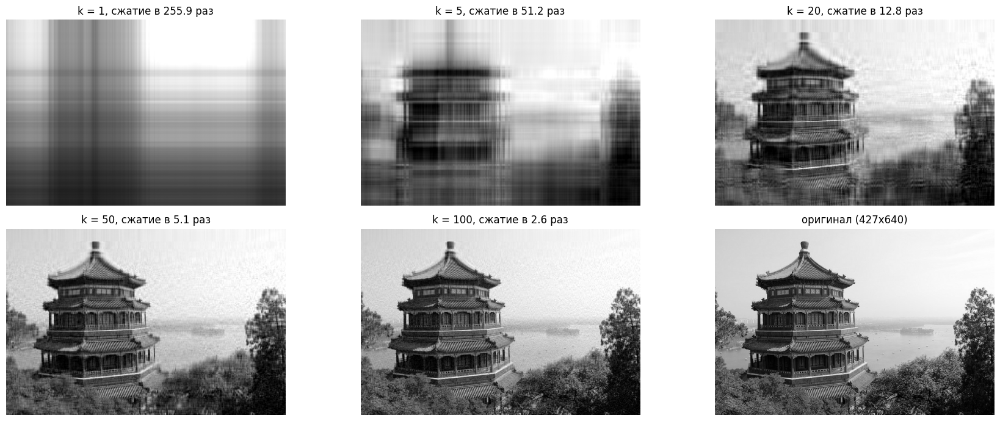

In [44]:
img = load_sample_image('china.jpg').mean(axis=2) / 255    # переводим в оттенки серого
m, n = img.shape
U_i, S_i, Vt_i = np.linalg.svd(img, full_matrices=False)

ks = [1, 5, 20, 50, 100]
plt.figure(figsize=(18, 7))
for j, k in enumerate(ks):
    approx = (U_i[:, :k] * S_i[:k]) @ Vt_i[:k]      # сумма первых k слоёв
    ratio = m * n / (k * (m + n + 1))
    plt.subplot(2, 3, j + 1)
    plt.imshow(approx, cmap='gray', vmin=0, vmax=1)
    plt.title(f'k = {k}, сжатие в {ratio:.1f} раз')
    plt.axis('off')
plt.subplot(2, 3, 6)
plt.imshow(img, cmap='gray')
plt.title(f'оригинал ({m}x{n})')
plt.axis('off')
plt.tight_layout()
plt.show()

А как выглядят отдельные «слои» $\sigma_i u_i v_i^T$? Первый задаёт общую картину яркости, следующие добавляют всё более мелкие детали.

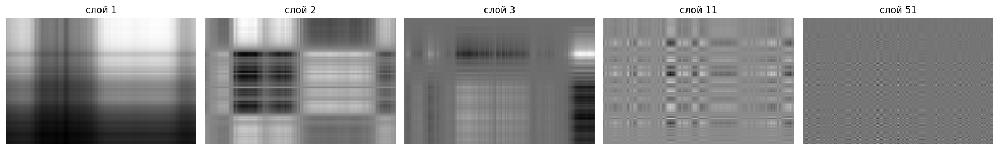

In [45]:
plt.figure(figsize=(18, 3.5))
for j, i in enumerate([0, 1, 2, 10, 50]):
    layer = S_i[i] * np.outer(U_i[:, i], Vt_i[i])
    plt.subplot(1, 5, j + 1)
    plt.imshow(layer, cmap='gray')
    plt.title(f'слой {i + 1}')
    plt.axis('off')
plt.tight_layout()
plt.show()

**Задание:** сделайте то же самое для цветной картинки (SVD отдельно для каждого из трёх каналов RGB). При каком $k$ вы перестаёте замечать разницу с оригиналом?

## Бонус: t-SNE - нелинейное понижение размерности для визуализации <a id="tsne"></a>

PCA — линейный метод: он может только «повернуть» данные и отбросить часть осей. Если структура в данных нелинейная (кольца, полумесяцы, многообразия), на двумерной проекции PCA группы часто накладываются друг на друга.

**t-SNE** (t-distributed Stochastic Neighbor Embedding, ван дер Маатен и Хинтон, 2008 решает другую задачу: найти такое расположение точек на плоскости, чтобы **соседи в исходном пространстве остались соседями на плоскости**.

Идея в двух шагах:
1. В исходном пространстве для каждой пары точек считаем «вероятность быть соседями» $p_{ij}$: чем ближе точки, тем она больше (используется гауссово ядро).
2. На плоскости задаём такие же вероятности $q_{ij}$, но через распределение Стьюдента (с «тяжёлыми хвостами»), и двигаем точки градиентным спуском, чтобы $q_{ij}$ были как можно ближе к $p_{ij}$ (минимизируем KL-дивергенцию).

Тяжёлые хвосты распределения Стьюдента позволяют далёким точкам на плоскости «разъехаться» сильнее, поэтому кластеры получаются хорошо разделёнными.

Важно понимать, чем t-SNE **не является**:
- это не преобразование признаков для модели: у `TSNE` нет метода `transform`, новые точки в готовую картинку не добавить;
- он сохраняет **локальную** структуру (кто чей сосед), а расстояния между далёкими кластерами и размеры кластеров на картинке ничего не значат;
- результат случайный и зависит от параметров.

Сравним PCA и t-SNE на датасете рукописных цифр.

### Данные: рукописные цифры

1797 картинок цифр от 0 до 9 размером $8 \times 8$ пикселей, то есть 64 признака.

(1797, 64)


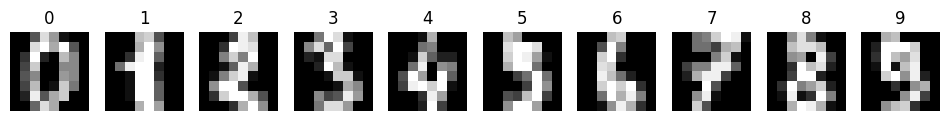

In [46]:
from sklearn.datasets import load_digits

digits = load_digits()
X_digits = digits.data      # матрица 1797 x 64: яркости пикселей
y_digits = digits.target    # какая цифра нарисована (0..9) — для раскраски, в обучении не используется

print(X_digits.shape)

plt.figure(figsize=(12, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_digits[i].reshape(8, 8), cmap='gray')
    plt.title(y_digits[i])
    plt.axis('off')
plt.show()

In [47]:
def plot_embedding(X_2d, y, title, ax=None):
    # Рисует двумерное представление, раскрашивая точки по классу (цифре)
    ax = ax or plt.figure(figsize=(9, 7)).gca()
    sc = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap='tab10', s=10, alpha=0.8)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])   # значения осей у t-SNE смысла не имеют
    return sc

### PCA: две главные компоненты

Метки цифр мы используем **только для раскраски** — оба метода работают без учителя.

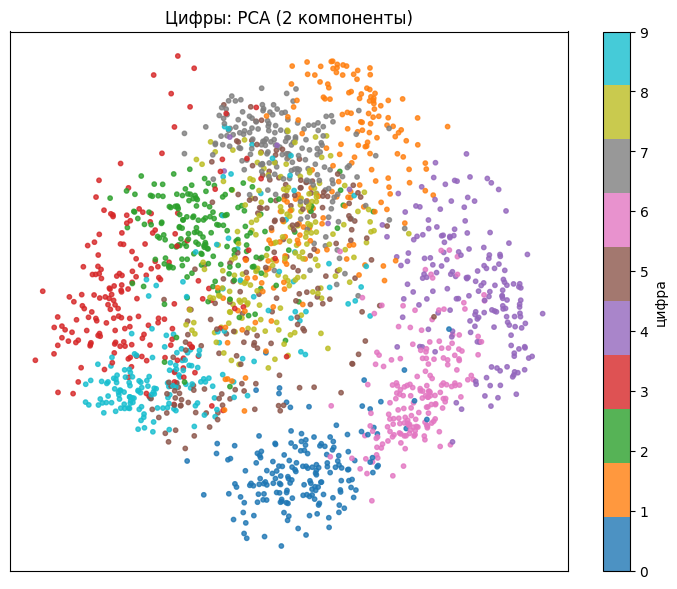

In [48]:
X_pca_digits = PCA(n_components=2).fit_transform(X_digits)

sc = plot_embedding(X_pca_digits, y_digits, 'Цифры: PCA (2 компоненты)')
plt.colorbar(sc, ticks=range(10), label='цифра')
plt.show()

Некоторые цифры (0, 4 и 6) отделяются, но большая часть классов накладывается друг на друга: две линейные проекции не могут «расплести» 64-мерные данные.

### t-SNE

Главный параметр — `perplexity`: грубо говоря, сколько соседей учитывает каждая точка (обычно 5–50, по умолчанию 30).

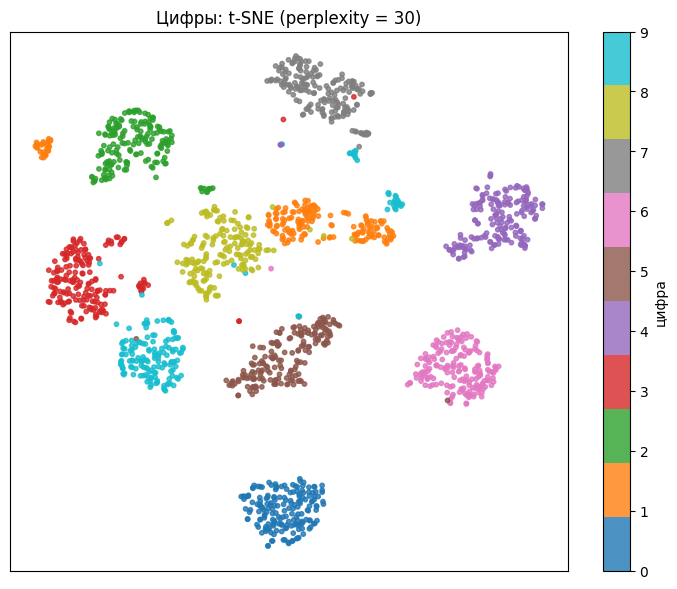

CPU times: user 15.4 s, sys: 44.1 ms, total: 15.5 s
Wall time: 15.5 s


In [49]:
%%time
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne_digits = tsne.fit_transform(X_digits)   # только fit_transform: метода transform у t-SNE нет

sc = plot_embedding(X_tsne_digits, y_digits, 'Цифры: t-SNE (perplexity = 30)')
plt.colorbar(sc, ticks=range(10), label='цифра')
plt.show()

Цифры разошлись в отдельные, почти не пересекающиеся облака — хотя меток метод не видел. Значит, в 64-мерном пространстве картинки одной цифры действительно лежат рядом, просто эта структура нелинейная и PCA её не показывает.

Отдельные точки «чужого» цвета внутри облака — обычно неаккуратно написанные цифры, похожие на другие (например, 1 и 7, 3 и 9).

### Влияние `perplexity`

Посмотрим, как меняется картинка при разных значениях параметра.

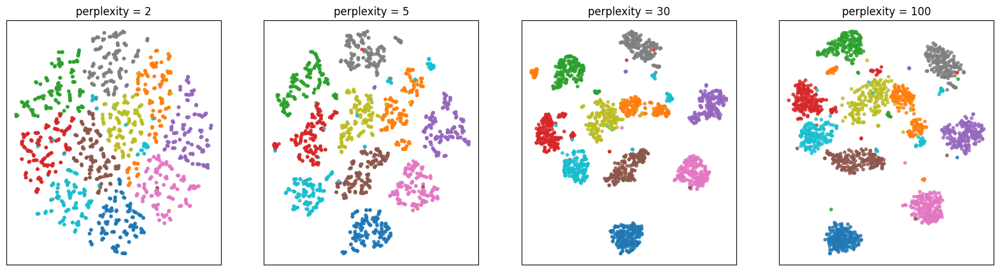

In [50]:
# ~1 минута
perplexities = [2, 5, 30, 100]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, p in zip(axes, perplexities):
    X_2d = TSNE(n_components=2, perplexity=p, random_state=42).fit_transform(X_digits)
    plot_embedding(X_2d, y_digits, f'perplexity = {p}', ax=ax)
plt.show()

- **Маленькая** `perplexity` (2): каждая точка смотрит только на пару ближайших соседей, поэтому облака получаются рыхлыми, с размытыми границами, а точки разных цифр перемешиваются по краям.
- **Средняя** (5–30): с ростом `perplexity` облака становятся всё компактнее; при 30 классы чётко разделены.
- **Большая** (100): учитывается более глобальная структура, облака по-прежнему разделены, но сближаются друг с другом.

Универсально правильного значения нет — стоит посмотреть на несколько.

### Влияние `random_state`

t-SNE начинает со случайного расположения точек и оптимизирует невыпуклую функцию, поэтому разные запуски дают разные картинки.

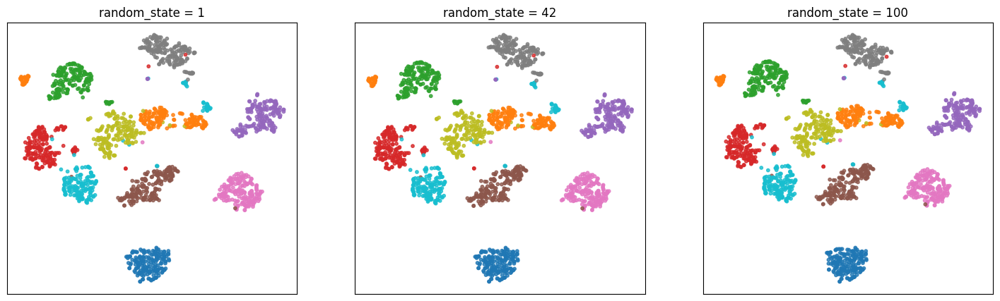

In [53]:
# ~1 минута
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, seed in zip(axes, [1, 42, 100]):
    X_2d = TSNE(n_components=2, perplexity=30, random_state=seed).fit_transform(X_digits)
    plot_embedding(X_2d, y_digits, f'random_state = {seed}', ax=ax)
plt.show()

Сами облака сохраняются (то, что цифры группируются, — устойчивый вывод), но их положение, взаимное расположение и форма меняются от запуска к запуску. Поэтому по картинке t-SNE **нельзя** делать выводы вида «кластер 3 ближе к кластеру 8, чем к кластеру 1» или «этот кластер больше». Выводы стоит проверять на нескольких запусках и на исходных данных.

### Снова лица: PCA против t-SNE

Вспомним картинку лиц на плоскости первых двух главных компонент: фото одного человека там не собирались в группы — компоненты описывали в основном освещение. Посмотрим, что покажет t-SNE на тех же 400 лицах.

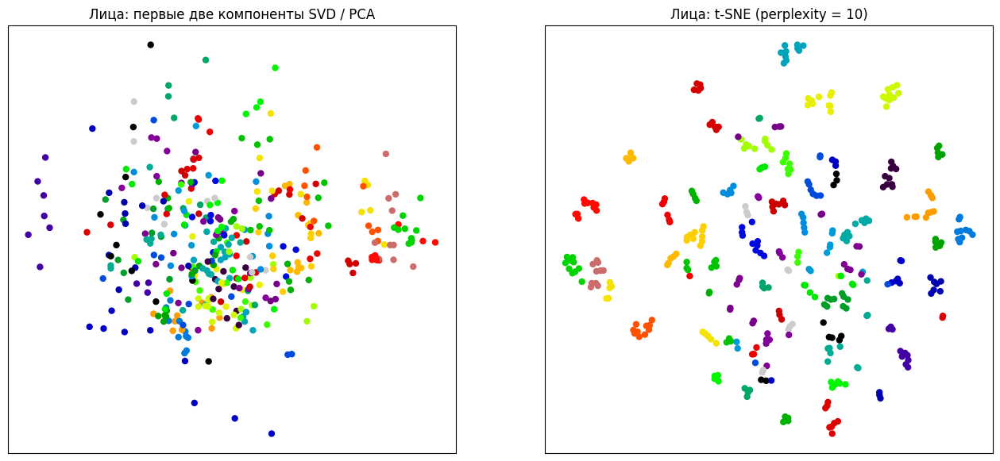

In [52]:
X_tsne_faces = TSNE(n_components=2, perplexity=10, random_state=42).fit_transform(X_faces)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].scatter(coords_all[:, 0], coords_all[:, 1], c=y_faces, cmap='nipy_spectral', s=25)
axes[0].set_title('Лица: первые две компоненты SVD / PCA')
axes[1].scatter(X_tsne_faces[:, 0], X_tsne_faces[:, 1], c=y_faces, cmap='nipy_spectral', s=25)
axes[1].set_title('Лица: t-SNE (perplexity = 10)')
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

Цвет — номер человека. У t-SNE фотографии одного человека в основном собираются в маленькие компактные группы (по 10 фото на человека, поэтому и `perplexity` взяли поменьше): соседями в пространстве пикселей оказываются фото того же человека. PCA на двух компонентах такой структуры не видит.

### Итого: когда что использовать

| | PCA / SVD | t-SNE |
|---|---|---|
| Тип | линейный | нелинейный |
| Что сохраняет | глобальную структуру, дисперсию | локальное соседство |
| Можно применить к новым данным | да (`transform`) | нет |
| Детерминированность | да | нет, зависит от `random_state` |
| Скорость | быстро | медленно на больших данных |
| Для чего | признаки для моделей, сжатие, шумоподавление, визуализация | **только визуализация** |

На практике их часто комбинируют: сначала PCA до 30–50 компонент (убрать шум и ускорить), потом t-SNE до 2.

Ещё один популярный нелинейный метод — [UMAP](https://umap-learn.readthedocs.io/en/latest/) (2018). Он похож на t-SNE, но работает быстрее, лучше сохраняет глобальную структуру и умеет преобразовывать новые точки (библиотека `umap-learn`).

## Итоги по понижению размерности

- PCA ищет ортогональные направления максимальной дисперсии; считается через SVD центрированной матрицы.
- Перед PCA данные **обязательно центрируют**, а признаки в разных единицах измерения — ещё и стандартизуют. PCA чувствителен к выбросам.
- Число компонент выбирают по доле объяснённой дисперсии (например, 90–95%) или по качеству итоговой модели.
- Усечённый SVD даёт наилучшее приближение матрицы низкого ранга — отсюда сжатие и шумоподавление.
- Ошибка восстановления по главным компонентам — простой и рабочий детектор аномалий.
- PCA — линейный метод: нелинейную структуру (кольца, полумесяцы) он не «развернёт».
- t-SNE — нелинейный метод **только для визуализации**: он сохраняет соседство точек, но не расстояния между группами; картинка зависит от `perplexity` и `random_state`.

### Полезные ссылки
- [How to Use t-SNE Effectively (Distill)](https://distill.pub/2016/misread-tsne/) — интерактивно о том, как не обмануться картинками t-SNE
- [Understanding UMAP](https://pair-code.github.io/understanding-umap/)
- [Singular Value Decomposition as Simply as Possible](https://gregorygundersen.com/blog/2018/12/10/svd/)
- [Как выбрать платье с помощью метода главных компонент (Хабр)](https://habr.com/ru/company/io/blog/265089/)
- [Интуиция PCA: собственные векторы и собственные значения (StackExchange)](https://stats.stackexchange.com/questions/2691/making-sense-of-principal-component-analysis-eigenvectors-eigenvalues)
- [Документация sklearn: разложение сигналов на компоненты](https://scikit-learn.org/stable/modules/decomposition.html)